In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/standardized_data.csv",
    dtype={"post_id": "string", "account_id": "string"}
)
df_clean = df.drop_duplicates(
    subset=["post_id"],
    keep="first"
).copy()

missing_data = df_clean.isnull().sum()

missing_report = pd.DataFrame({
    "Missing Values": missing_data,
    "Persentase (%)": (
        missing_data / len(df_clean) * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        by="Missing Values",
        ascending=False
    )
)

,Missing Values,Persentase (%)
target_username,279,67.07
target_account_id,279,67.07
target_post_id,279,67.07
bio,31,7.45
id,0,0.00
post_id,0,0.00
account_id,0,0.00
source_account_id,0,0.00
source_post_id,0,0.00
relation_type,0,0.00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/standardized_data.csv",
    dtype={"post_id": "string", "account_id": "string"}
)

df_clean = df.drop_duplicates(
    subset=["post_id"],
    keep="first"
).copy()

target_check = df_clean.groupby("relation_type").agg(
    total_post=("post_id", "count"),
    missing_target_post=("target_post_id", "count"),
)

target_check["missing_target_post"] = (
    df_clean.groupby("relation_type")["target_post_id"]
    .apply(lambda x: x.isna().sum())
)

target_check["persentase_missing"] = (
    target_check["missing_target_post"]
    / target_check["total_post"] * 100
).round(2)

display(target_check)

# print("Jumlah akun:", len(posts_per_account))
# print("Rata-rata post per akun:", round(posts_per_account.mean(), 2))
# print("Median post per akun:", posts_per_account.median())
# print("Post terbanyak oleh satu akun:", posts_per_account.max())



,total_post,missing_target_post,persentase_missing
relation_type,,,
original,279,279,100.0
quote,95,0,0.0
reply,42,0,0.0


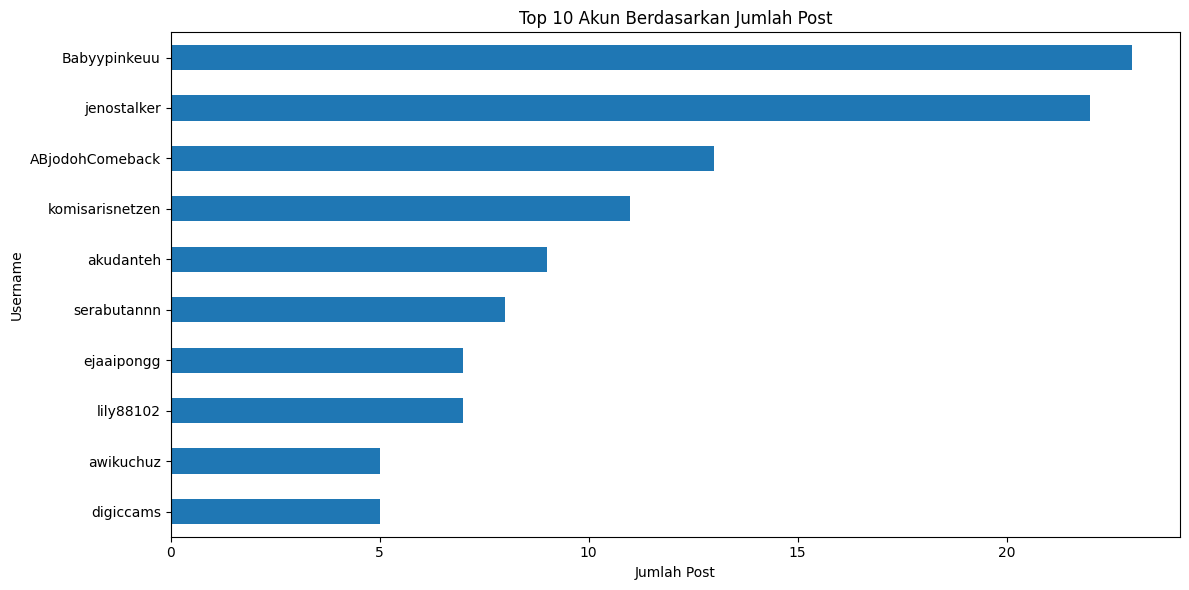

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/standardized_data.csv",
    dtype={"post_id": "string", "account_id": "string"}
)

posts_per_account = (
    df_clean.groupby("username")["post_id"]
    .nunique()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

posts_per_account.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Akun Berdasarkan Jumlah Post")
plt.xlabel("Jumlah Post")
plt.ylabel("Username")
plt.tight_layout()
plt.show()

distribusi aktivitas akun

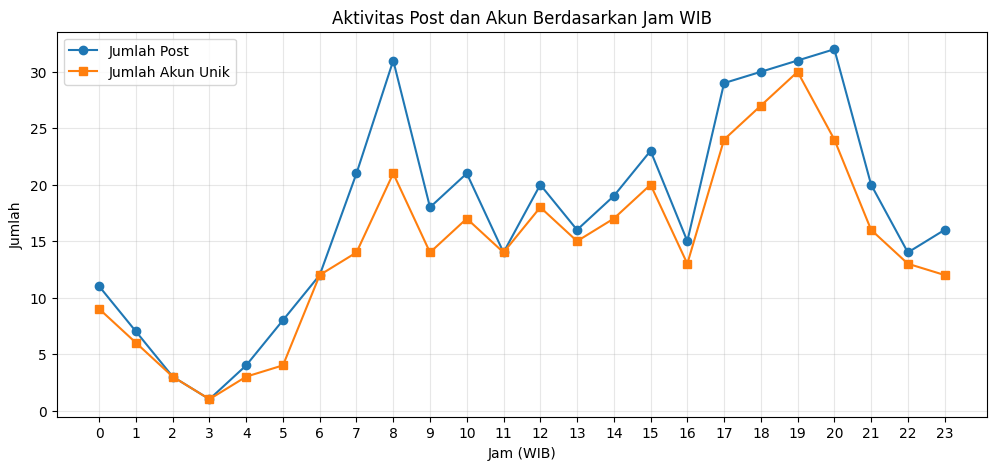

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/standardized_data.csv",
    dtype={"post_id": "string", "account_id": "string"}
)

df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    utc=True,
    errors="coerce"
)

df_time = df_clean.dropna(subset=["date"]).copy()

df_time["date_wib"] = (
    pd.to_datetime(df_time["date"], utc=True)
    .dt.tz_convert("Asia/Jakarta")
)

df_time["hour_wib"] = df_time["date_wib"].dt.hour

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_activity.index,
    hourly_activity["total_posts"],
    marker="o",
    label="Jumlah Post"
)

plt.plot(
    hourly_activity.index,
    hourly_activity["unique_accounts"],
    marker="s",
    label="Jumlah Akun Unik"
)

plt.title("Aktivitas Post dan Akun Berdasarkan Jam WIB")
plt.xlabel("Jam (WIB)")
plt.ylabel("Jumlah")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()

plt.show()



10 interval dengan aktivitas tertinggi:


,post_id
date_wib,
2026-11-03 08:10:00+07:00,5
2026-11-03 23:50:00+07:00,4
2026-10-12 20:20:00+07:00,3
2026-11-02 12:50:00+07:00,3
2026-11-02 19:30:00+07:00,3
2026-10-11 10:20:00+07:00,3
2026-10-15 08:30:00+07:00,3
2026-11-03 01:40:00+07:00,3
2026-11-02 17:10:00+07:00,3


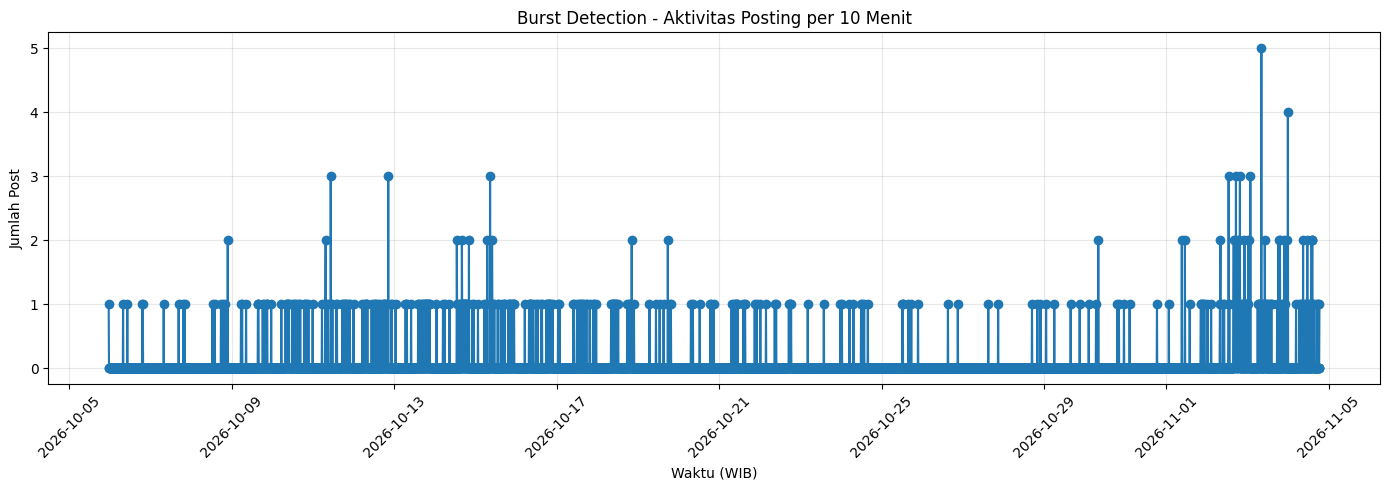

,total_posts,unique_accounts
date_wib,,
2026-11-03 08:10:00+07:00,5,3
2026-10-12 20:20:00+07:00,3,3
2026-10-15 08:30:00+07:00,3,3
2026-11-04 14:20:00+07:00,2,2
2026-11-04 14:10:00+07:00,2,2
2026-11-04 13:50:00+07:00,2,2
2026-10-19 17:30:00+07:00,2,2
2026-10-08 21:30:00+07:00,2,2
2026-11-03 21:50:00+07:00,2,2


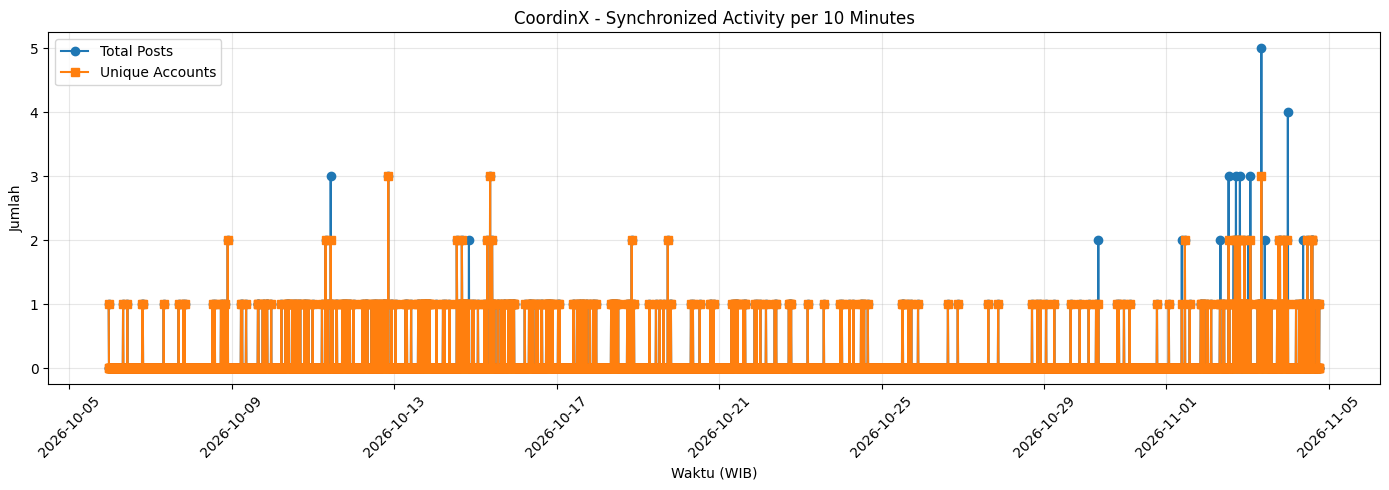

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/standardized_data.csv",
    dtype={"post_id": "string", "account_id": "string"}
)

df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    utc=True,
    errors="coerce"
)

df_time = df_clean.dropna(subset=["date"]).copy()

df_time["date_wib"] = (
    pd.to_datetime(df_time["date"], utc=True)
    .dt.tz_convert("Asia/Jakarta")
)

df_time = df_time.set_index("date_wib")

burst_activity = (
    df_time["post_id"]
    .resample("10min")
    .nunique()
)

print("10 interval dengan aktivitas tertinggi:")

display(
    burst_activity
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(14, 5))

plt.plot(
    burst_activity.index,
    burst_activity.values,
    marker="o"
)

plt.title("Burst Detection - Aktivitas Posting per 10 Menit")
plt.xlabel("Waktu (WIB)")
plt.ylabel("Jumlah Post")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

mean_activity = burst_activity.mean()
std_activity = burst_activity.std()

threshold = mean_activity + (2 * std_activity)

burst_periods = burst_activity[
    burst_activity > threshold
]

burst_analysis = (
    df_time
    .resample("10min")
    .agg(
        total_posts=("post_id", "nunique"),
        unique_accounts=("account_id", "nunique")
    )
)

top_synchronized = burst_analysis.sort_values(
    by="unique_accounts",
    ascending=False
).head(10)

display(top_synchronized)

plt.figure(figsize=(14, 5))

plt.plot(
    burst_analysis.index,
    burst_analysis["total_posts"],
    marker="o",
    label="Total Posts"
)

plt.plot(
    burst_analysis.index,
    burst_analysis["unique_accounts"],
    marker="s",
    label="Unique Accounts"
)

plt.title("CoordinX - Synchronized Activity per 10 Minutes")
plt.xlabel("Waktu (WIB)")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



,total_posts,unique_accounts
date_wib,,
2026-11-03 08:10:00+07:00,5,3
2026-10-12 20:20:00+07:00,3,3
2026-10-15 08:30:00+07:00,3,3
2026-11-04 14:20:00+07:00,2,2
2026-11-04 14:10:00+07:00,2,2
2026-11-04 13:50:00+07:00,2,2
2026-10-19 17:30:00+07:00,2,2
2026-10-08 21:30:00+07:00,2,2
2026-11-03 21:50:00+07:00,2,2


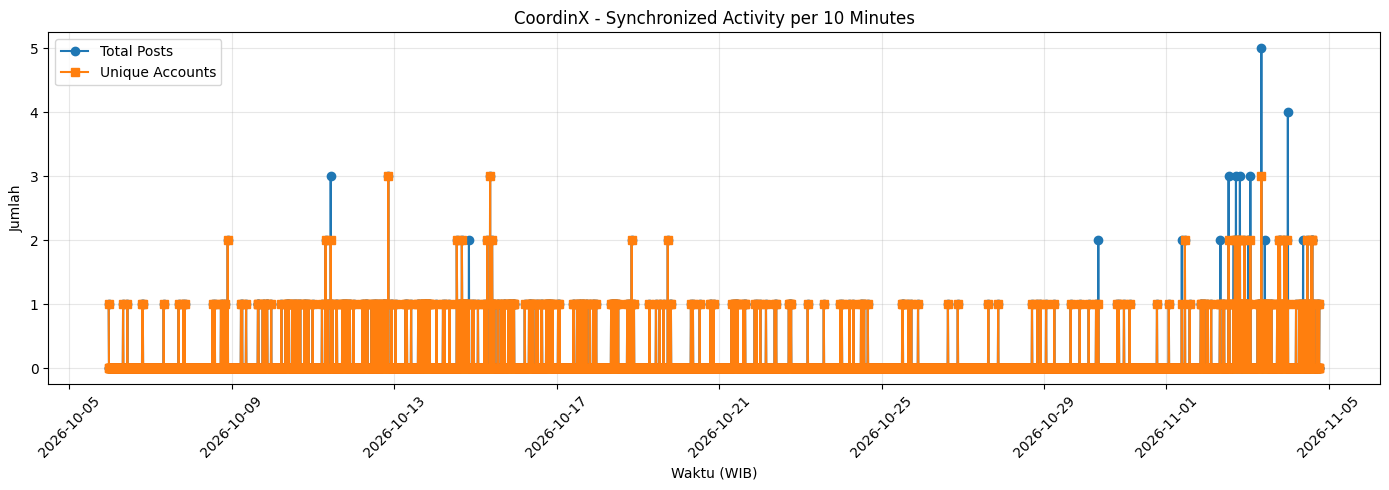

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "/content/standardized_data.csv",
    dtype={"post_id": "string", "account_id": "string"}
)

df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    utc=True,
    errors="coerce"
)

df_time = df_clean.dropna(subset=["date"]).copy()

df_time["date_wib"] = (
    pd.to_datetime(df_time["date"], utc=True)
    .dt.tz_convert("Asia/Jakarta")
)

df_time = df_time.set_index("date_wib")


burst_analysis = (
    df_time
    .resample("10min")
    .agg(
        total_posts=("post_id", "nunique"),
        unique_accounts=("account_id", "nunique")
    )
)

top_synchronized = burst_analysis.sort_values(
    by="unique_accounts",
    ascending=False
).head(10)

display(top_synchronized)

plt.figure(figsize=(14, 5))

plt.plot(
    burst_analysis.index,
    burst_analysis["total_posts"],
    marker="o",
    label="Total Posts"
)

plt.plot(
    burst_analysis.index,
    burst_analysis["unique_accounts"],
    marker="s",
    label="Unique Accounts"
)

plt.title("CoordinX - Synchronized Activity per 10 Minutes")
plt.xlabel("Waktu (WIB)")
plt.ylabel("Jumlah")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



Jumlah post: 416
Ukuran TF-IDF: (416, 5000)


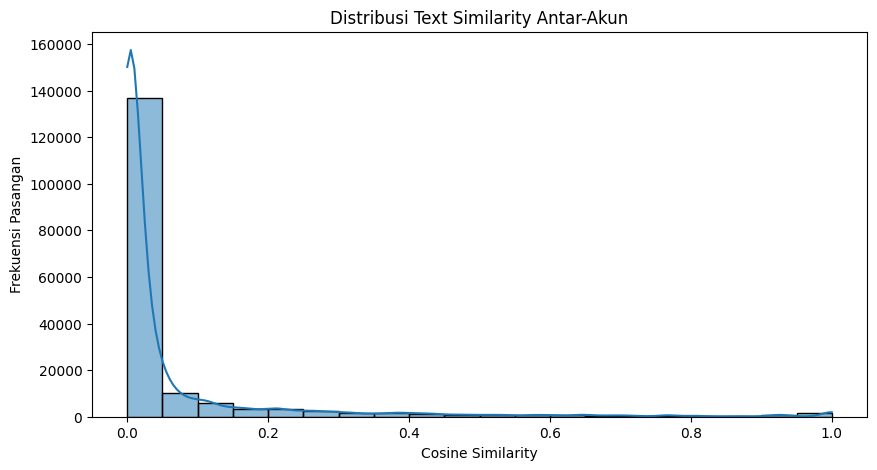

Jumlah pasangan: 173056
Rata-rata: 0.0649
Median: 0.0061
Tertinggi: 1.0


In [ ]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df_text = df_clean.copy()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df_text["clean_text"] = df_text["text"].apply(clean_text)

df_text = df_text[
    df_text["clean_text"].str.len() > 0
].reset_index(drop=True)

print("Jumlah post:", len(df_text))

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    max_features=5000
)

tfidf_matrix = vectorizer.fit_transform(
    df_text["clean_text"]
)

similarity_matrix = cosine_similarity(tfidf_matrix)

print("Ukuran TF-IDF:", tfidf_matrix.shape)
valid_similarities = similarity_matrix[
    similarity_matrix >= 0
]

plt.figure(figsize=(10, 5))

sns.histplot(
    valid_similarities,
    bins=20,
    kde=True
)

plt.title("Distribusi Text Similarity Antar-Akun")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frekuensi Pasangan")

plt.show()

print("Jumlah pasangan:", len(valid_similarities))
print("Rata-rata:", round(valid_similarities.mean(), 4))
print("Median:", round(np.median(valid_similarities), 4))
print("Tertinggi:", round(valid_similarities.max(), 4))


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd
df_analysis = df_analysis.reset_index(drop=True)

def calculate_similarity_pairs(df, text_column, threshold=0.3):
    texts = df[text_column].fillna("").astype(str)
    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=1,
        max_features=5000
    )

    tfidf = vectorizer.fit_transform(texts)
    matrix = cosine_similarity(tfidf)
    accounts = (
        df["username"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
        .to_numpy()
    )
    upper_triangle = np.triu(
        np.ones(matrix.shape, dtype=bool),
        k=1
    )

    different_accounts = (
        accounts[:, None] != accounts[None, :]
    )
    non_empty = (
        (np.asarray(tfidf.getnnz(axis=1)).ravel() > 0)
    )

    valid_pairs = (
        upper_triangle
        & different_accounts
        & non_empty[:, None]
        & non_empty[None, :]
        & (matrix >= threshold)
    )

    rows, cols = np.where(valid_pairs)

    results = []

    for i, j in zip(rows, cols):
        results.append({
            "account_1": accounts[i],
            "account_2": accounts[j],
            "post_1": texts.iloc[i],
            "post_2": texts.iloc[j],
            "similarity": matrix[i, j]
        })

    result_df = pd.DataFrame(results)

    if not result_df.empty:
        result_df = result_df.sort_values(
            "similarity",
            ascending=False
        ).reset_index(drop=True)

    return result_df, matrix
hashtag_pairs, hashtag_matrix = calculate_similarity_pairs(
    df_analysis,
    "hashtags",
    threshold=0.3
)
narrative_pairs, narrative_matrix = calculate_similarity_pairs(
    df_analysis,
    "narrative",
    threshold=0.3
)
print("HASHTAG SIMILARITY")
print("Jumlah pasangan:", len(hashtag_pairs))
display(hashtag_pairs.head(10))

print("\nNARRATIVE SIMILARITY")
print("Jumlah pasangan:", len(narrative_pairs))
display(narrative_pairs.head(10))

HASHTAG SIMILARITY
Jumlah pasangan: 16826


,account_1,account_2,post_1,post_2,similarity
0,nanaissence,akudanteh,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0
1,ubematcha2,diedpoolsz,#karhutla #prayforkalimantan,#karhutla #prayforkalimantan,1.0
2,ubematcha2,putrikariimah,#karhutla #prayforkalimantan,#karhutla #prayforkalimantan,1.0
3,nanaissence,akudanteh,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0
4,nanaissence,madisojn,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0
5,nanaissence,cleonelion,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0
6,akudanteh,fillilabs,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0
7,nanaissence,_06kayyina23_,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0
8,akudanteh,madisojn,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0
9,nanaissence,mwduyt,#prayforlampung #prayforsulawesi #prayforkalim...,#prayforlampung #prayforsulawesi #prayforkalim...,1.0



NARRATIVE SIMILARITY
Jumlah pasangan: 401


,account_1,account_2,post_1,post_2,similarity
0,pancakeduriaaan,audinn3,tetap berisik,tetap berisik!!!,1.0
1,pancakeduriaaan,pinkeaasy,tetap berisik,tetap berisik,1.0
2,babyypinkeuu,areyoutala,tetap berisik,tetap berisik,1.0
3,babyypinkeuu,mekhala94,tetap berisik,tetap berisik,1.0
4,audinn3,alayaharsa,tetap berisik!!!,tetap berisik,1.0
5,audinn3,mekhala94,tetap berisik!!!,tetap berisik,1.0
6,alayaharsa,areyoutala,tetap berisik,tetap berisik,1.0
7,alayaharsa,mekhala94,tetap berisik,tetap berisik,1.0
8,audinn3,areyoutala,tetap berisik!!!,tetap berisik,1.0
9,mekhala94,areyoutala,tetap berisik,tetap berisik,1.0


In [ ]:
df_analysis["narrative_word_count"] = (
    df_analysis["narrative"]
    .str.split()
    .str.len()
)

df_analysis["hashtag_count"] = (
    df_analysis["hashtags"]
    .str.findall(r"#\w+")
    .str.len()
)
print("Statistik jumlah kata narasi:")
display(
    df_analysis["narrative_word_count"].describe()
)

print("\nDistribusi jumlah hashtag:")
display(
    df_analysis["hashtag_count"].describe()
)

df_narrative_long = df_analysis[
    df_analysis["narrative_word_count"] >= 4
].copy()

narrative_pairs_long, narrative_matrix_long = (
    calculate_similarity_pairs(
        df_narrative_long,
        "narrative",
        threshold=0.3
    )
)

print("Post dengan minimal 4 kata:",
      len(df_narrative_long))

print("Pasangan narrative similarity:",
      len(narrative_pairs_long))

display(narrative_pairs_long.head(20))

Statistik jumlah kata narasi:


,narrative_word_count
count,416.000000
mean,15.262019
std,15.354167
min,0.000000
25%,3.000000
50%,11.000000
75%,23.000000
max,121.000000



Distribusi jumlah hashtag:


,hashtag_count
count,416.000000
mean,5.403846
std,5.156854
min,0.000000
25%,1.000000
50%,3.000000
75%,10.250000
max,15.000000


Post dengan minimal 4 kata: 306
Pasangan narrative similarity: 158


,account_1,account_2,post_1,post_2,similarity
0,naraeraa,dubidamskii,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,all eyes on kalimantan!!!,1.0
1,chrngelique,babyypinkeuu,"and if we burn, you burn with us","and if we burn, you burn with us",1.0
2,chrngelique,babyypinkeuu,"and if we burn, you burn with us","and if we burn, you burn with us",1.0
3,kimchigyus,skylov3ly,guys please dont stop talking and stalking abo...,guys please dont stop talking and stalking abo...,1.0
4,babyypinkeuu,jenostalker,guys please dont stop talking and stalking abo...,guys please dont stop talking and stalking abo...,1.0
5,babyypinkeuu,skylov3ly,guys please dont stop talking and stalking abo...,guys please dont stop talking and stalking abo...,1.0
6,babyypinkeuu,rahasxya,guys please dont stop talking and stalking abo...,guys please dont stop talking and stalking abo...,1.0
7,babyypinkeuu,skylov3ly,guys please dont stop talking and stalking abo...,guys please dont stop talking and stalking abo...,1.0
8,babyypinkeuu,kimchigyus,guys please dont stop talking and stalking abo...,guys please dont stop talking and stalking abo...,1.0
9,babyypinkeuu,kisaakasih,guys please dont stop talking and stalking abo...,guys please dont stop talking and stalking abo...,1.0


In [ ]:
account_similarity = (
    narrative_pairs_long
    .groupby(["account_1", "account_2"])
    .agg(
        similar_post_pairs=("similarity", "count"),
        max_similarity=("similarity", "max"),
        avg_similarity=("similarity", "mean")
    )
    .reset_index()
)

account_similarity = account_similarity.sort_values(
    by=["similar_post_pairs", "max_similarity"],
    ascending=False
)

print("Jumlah pasangan akun unik:", len(account_similarity))

display(account_similarity.head(20))

Jumlah pasangan akun unik: 122


,account_1,account_2,similar_post_pairs,max_similarity,avg_similarity
13,babyypinkeuu,ainuraenij0,10,0.385378,0.354123
15,babyypinkeuu,jenostalker,3,1.000000,0.942300
17,babyypinkeuu,kimchigyus,3,1.000000,0.942300
18,babyypinkeuu,kisaakasih,3,1.000000,0.942300
24,babyypinkeuu,rahasxya,3,1.000000,0.942300
25,babyypinkeuu,skylov3ly,3,1.000000,0.942300
20,babyypinkeuu,mariesbasee_,3,0.981840,0.925341
21,babyypinkeuu,mgenfox,3,0.670032,0.631746
23,babyypinkeuu,onyourremm02_,3,0.659454,0.618639
19,babyypinkeuu,lovekonoo,3,0.498310,0.469836


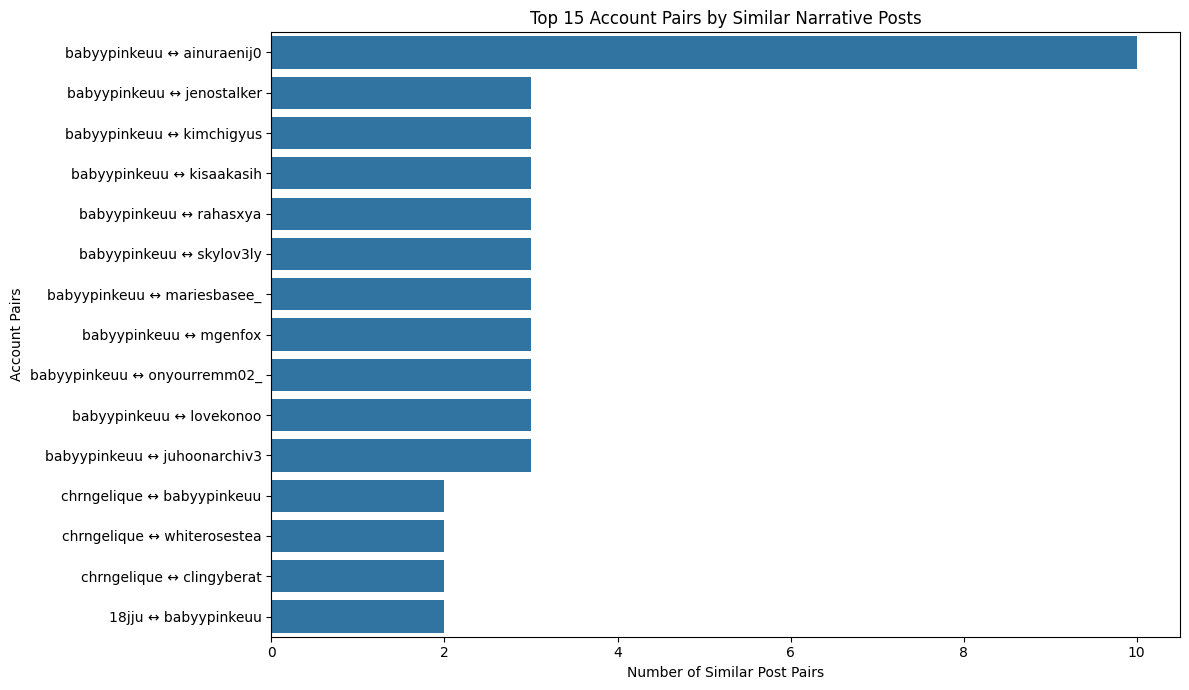

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

top_pairs = account_similarity.head(15).copy()

top_pairs["account_pair"] = (
    top_pairs["account_1"] + " ↔ " +
    top_pairs["account_2"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_pairs,
    x="similar_post_pairs",
    y="account_pair"
)

plt.title("Top 15 Account Pairs by Similar Narrative Posts")
plt.xlabel("Number of Similar Post Pairs")
plt.ylabel("Account Pairs")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def calculate_similarity_with_time(
    df,
    text_column="narrative",
    threshold=0.3
):
    data = df.copy().reset_index(drop=True)

    texts = data[text_column].fillna("").astype(str)

    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=1,
        max_features=5000
    )

    tfidf = vectorizer.fit_transform(texts)
    matrix = cosine_similarity(tfidf)

    accounts = data["account_id"].fillna(
        data["username"]
    ).astype(str).to_numpy()

    non_empty = np.asarray(tfidf.getnnz(axis=1)).ravel() > 0

    valid_pairs = (
        np.triu(np.ones(matrix.shape, dtype=bool), k=1)
        & (accounts[:, None] != accounts[None, :])
        & non_empty[:, None]
        & non_empty[None, :]
        & (matrix >= threshold)
    )

    rows, cols = np.where(valid_pairs)

    results = []

    for i, j in zip(rows, cols):
        post_a = data.iloc[i]
        post_b = data.iloc[j]

        results.append({
            "account_1": post_a["username"],
            "account_2": post_b["username"],
            "post_id_1": post_a["post_id"],
            "post_id_2": post_b["post_id"],
            "date_1": post_a["date"],
            "date_2": post_b["date"],
            "post_1": post_a[text_column],
            "post_2": post_b[text_column],
            "similarity": matrix[i, j]
        })

    result_df = pd.DataFrame(results)

    return result_df, matrix


In [ ]:
narrative_pairs_time, narrative_matrix_time = (
    calculate_similarity_with_time(
        df_narrative_long,
        text_column="narrative",
        threshold=0.3
    )
)

display(narrative_pairs_time.head(10))

,account_1,account_2,post_id_1,post_id_2,date_1,date_2,post_1,post_2,similarity
0,naraeraa,oqforwhat,2117897733009006713,2117446623039262734,2026-11-04 08:32:22+00:00,2026-11-03 02:39:49+00:00,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,all eyes on papua ‼️,0.676305
1,naraeraa,seanvrs,2117897733009006713,2111807338529317133,2026-11-04 08:32:22+00:00,2026-10-18 13:11:19+00:00,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,‼️ all eyes on indonesia ‼️,0.692861
2,naraeraa,hazellevl,2117897733009006713,2110550391708639360,2026-11-04 08:32:22+00:00,2026-10-15 01:56:40+00:00,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,let's all focus on what's happening &amp; not ...,0.374505
3,naraeraa,Dubidamskii,2117897733009006713,2110292080333558256,2026-11-04 08:32:22+00:00,2026-10-14 08:50:13+00:00,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,all eyes on kalimantan!!!,1.000000
4,naraeraa,jimination_co,2117897733009006713,2110294128500379720,2026-11-04 08:32:22+00:00,2026-10-14 08:58:22+00:00,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,"eyes on kalimantan, eyes on indonesia!",0.685915
5,naraeraa,flllowiee,2117897733009006713,2109904462068478216,2026-11-04 08:32:22+00:00,2026-10-13 07:09:58+00:00,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,"guys keep our eyes on kalimantan yaa,",0.419713
6,naraeraa,ejaaipongg,2117897733009006713,2109585086400360549,2026-11-04 08:32:22+00:00,2026-10-12 10:00:53+00:00,all eyes on kalimantan ❤️‍🔥❤️‍🔥❤️‍🔥,lihat kawan. api nya uda sampe pemukiman warga...,0.483821
7,Babyypinkeuu,AiNuraenij0,2117881446795005957,2109123866438304173,2026-11-04 07:27:39+00:00,2026-10-11 03:28:10+00:00,up up jangan sampai redup guys,up up up!!! dibakarnya hutan dan lahan,0.339690
8,Babyypinkeuu,AiNuraenij0,2117881446795005957,2109123822385603053,2026-11-04 07:27:39+00:00,2026-10-11 03:27:59+00:00,up up jangan sampai redup guys,up up up!!! dibakarnya hutan dan lahan,0.339690
9,whiterosestea,QueenOfHeaven30,2117777613825720809,2117612451026116769,2026-11-04 00:35:04+00:00,2026-11-03 13:38:46+00:00,prabowo disadap itu cuma pengalihan isu biar d...,prabowo disadap itu cuma pengalihan isu biar d...,0.509739


,account_1,account_2,similarity,time_difference_minutes
91,nndoweirs,mgenfox,0.523091,8.016667
121,Dubidamskii,jimination_co,0.685915,8.150000
140,mariesbasee_,skylov3ly,0.981840,33.633333
50,PutriKariimah,jenostalker,0.648289,50.566667
20,chrngelique,Babyypinkeuu,1.000000,52.050000
17,chrngelique,Babyypinkeuu,1.000000,55.400000
156,juhoonarchiv3,rahasxya,0.427741,59.316667
133,kisaakasih,mariesbasee_,0.981840,107.383333
148,skylov3ly,onyourremm02_,0.659454,127.866667
135,kisaakasih,skylov3ly,1.000000,141.016667


,time_group,number_of_pairs
0,Lebih dari 24 jam,122
1,1-24 jam,29
2,15-60 menit,5
3,5-15 menit,2


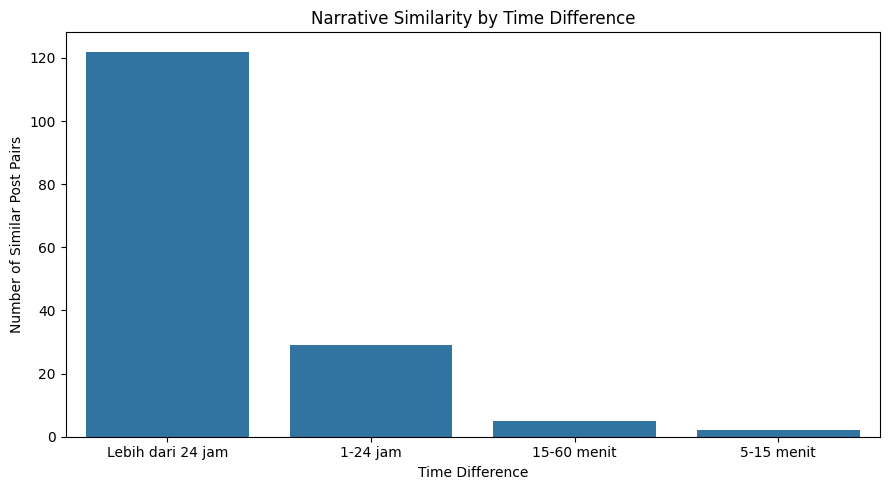

In [ ]:
narrative_pairs_time["date_1"] = pd.to_datetime(
    narrative_pairs_time["date_1"], utc=True
)

narrative_pairs_time["date_2"] = pd.to_datetime(
    narrative_pairs_time["date_2"], utc=True
)

narrative_pairs_time["time_difference_minutes"] = (
    narrative_pairs_time["date_1"]
    .sub(narrative_pairs_time["date_2"])
    .abs()
    .dt.total_seconds() / 60
)

display(
    narrative_pairs_time[
        [
            "account_1",
            "account_2",
            "similarity",
            "time_difference_minutes"
        ]
    ].sort_values("time_difference_minutes").head(20)
)

def classify_time(minutes):
    if minutes <= 5:
        return "0-5 menit"
    elif minutes <= 15:
        return "5-15 menit"
    elif minutes <= 60:
        return "15-60 menit"
    elif minutes <= 1440:
        return "1-24 jam"
    else:
        return "Lebih dari 24 jam"

narrative_pairs_time["time_group"] = (
    narrative_pairs_time["time_difference_minutes"]
    .apply(classify_time)
)

time_summary = (
    narrative_pairs_time["time_group"]
    .value_counts()
    .rename_axis("time_group")
    .reset_index(name="number_of_pairs")
)

display(time_summary)

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=time_summary,
    x="time_group",
    y="number_of_pairs"
)

plt.title("Narrative Similarity by Time Difference")
plt.xlabel("Time Difference")
plt.ylabel("Number of Similar Post Pairs")

plt.tight_layout()
plt.show()

In [ ]:
candidate_pairs = (
    narrative_pairs_time[
        narrative_pairs_time["time_difference_minutes"] <= 60
    ]
    .copy()
    .sort_values("time_difference_minutes")
)

candidate_pairs["date_1_wib"] = (
    candidate_pairs["date_1"].dt.tz_convert("Asia/Jakarta")
)

candidate_pairs["date_2_wib"] = (
    candidate_pairs["date_2"].dt.tz_convert("Asia/Jakarta")
)

columns_to_show = [
    "account_1",
    "account_2",
    "similarity",
    "time_difference_minutes",
    "date_1_wib",
    "date_2_wib",
    "post_1",
    "post_2"
]

pd.set_option("display.max_colwidth", None)

display(candidate_pairs[columns_to_show])

,account_1,account_2,similarity,time_difference_minutes,date_1_wib,date_2_wib,post_1,post_2
91,nndoweirs,mgenfox,0.523091,8.016667,2026-10-16 19:18:11+07:00,2026-10-16 19:26:12+07:00,"sedikit dari aku, yang gak pandai menulis, tapi mau coba mengungkapkan keresahan. this is not ai, not hell, this is karhutla. [maaf jika masih banyak kurangnya]","this is not ai, not hell, this is karhutla."
121,Dubidamskii,jimination_co,0.685915,8.150000,2026-10-14 15:50:13+07:00,2026-10-14 15:58:22+07:00,all eyes on kalimantan!!!,"eyes on kalimantan, eyes on indonesia!"
140,mariesbasee_,skylov3ly,0.981840,33.633333,2026-10-12 20:26:13+07:00,2026-10-12 19:52:35+07:00,"please dont stop talking and stalking about karhutla. this is not ai, not hell, this is karhutla. up up up!!!","guys please dont stop talking and stalking about karhutla. this is not ai, not hell, this is karhutla. up up up!!!"
50,PutriKariimah,jenostalker,0.648289,50.566667,2026-10-22 17:56:54+07:00,2026-10-22 17:06:20+07:00,peringatan bahaya sudah menyala! sore ini sudah ada 14.000 sedang dan 1000 lebih titik api tinggi di kalimantan!,alert alert alert!!!! guys sore ini sudah ada 14.000 lebih titik api sedang dan 1000 lebih titik api tinggi di kalimantan.
20,chrngelique,Babyypinkeuu,1.000000,52.050000,2026-11-03 21:46:58+07:00,2026-11-03 20:54:55+07:00,"and if we burn, you burn with us","and if we burn, you burn with us"
17,chrngelique,Babyypinkeuu,1.000000,55.400000,2026-11-03 21:50:19+07:00,2026-11-03 20:54:55+07:00,"and if we burn, you burn with us","and if we burn, you burn with us"
156,juhoonarchiv3,rahasxya,0.427741,59.316667,2026-10-12 06:07:19+07:00,2026-10-12 05:08:00+07:00,"indonesia belum pulih, dan pemerintah pusat hanya sibuk menarik pajak rakyat yang mencekik this is not ai, not hell, this is karhutla.","guys please dont stop talking and stalking about karhutla. this is not ai, not hell, this is karhutla. up up up!!!"


In [ ]:
import re
from collections import Counter

def get_shared_words(text1, text2):
    words1 = set(re.findall(r"\b\w+\b", str(text1).lower()))
    words2 = set(re.findall(r"\b\w+\b", str(text2).lower()))

    stopwords = {
        "dan", "yang", "di", "ke", "dari", "ini", "itu",
        "the", "and", "is", "are", "to", "of", "about",
        "for", "with", "not", "on", "up", "guys"
    }

    shared = (words1 & words2) - stopwords

    return ", ".join(sorted(shared))


candidate_pairs["shared_words"] = candidate_pairs.apply(
    lambda row: get_shared_words(
        row["post_1"],
        row["post_2"]
    ),
    axis=1
)

display(
    candidate_pairs[
        [
            "account_1",
            "account_2",
            "similarity",
            "time_difference_minutes",
            "shared_words"
        ]
    ]
)

evidence_pairs = candidate_pairs.copy()

evidence_pairs["text_similarity"] = evidence_pairs["similarity"]

evidence_pairs["temporal_proximity_minutes"] = (
    evidence_pairs["time_difference_minutes"]
)

evidence_pairs["manual_review"] = "pending"

evidence_pairs["evidence_note"] = ""

evidence_pairs = evidence_pairs[
    [
        "account_1",
        "account_2",
        "text_similarity",
        "temporal_proximity_minutes",
        "shared_words",
        "manual_review",
        "evidence_note"
    ]
]

display(evidence_pairs)

,account_1,account_2,similarity,time_difference_minutes,shared_words
91,nndoweirs,mgenfox,0.523091,8.016667,"ai, hell, karhutla, this"
121,Dubidamskii,jimination_co,0.685915,8.150000,"eyes, kalimantan"
140,mariesbasee_,skylov3ly,0.981840,33.633333,"ai, dont, hell, karhutla, please, stalking, stop, talking, this"
50,PutriKariimah,jenostalker,0.648289,50.566667,"000, 1000, 14, ada, api, kalimantan, lebih, sedang, sore, sudah, tinggi, titik"
20,chrngelique,Babyypinkeuu,1.000000,52.050000,"burn, if, us, we, you"
17,chrngelique,Babyypinkeuu,1.000000,55.400000,"burn, if, us, we, you"
156,juhoonarchiv3,rahasxya,0.427741,59.316667,"ai, hell, karhutla, this"


,account_1,account_2,text_similarity,temporal_proximity_minutes,shared_words,manual_review,evidence_note
91,nndoweirs,mgenfox,0.523091,8.016667,"ai, hell, karhutla, this",pending,
121,Dubidamskii,jimination_co,0.685915,8.150000,"eyes, kalimantan",pending,
140,mariesbasee_,skylov3ly,0.981840,33.633333,"ai, dont, hell, karhutla, please, stalking, stop, talking, this",pending,
50,PutriKariimah,jenostalker,0.648289,50.566667,"000, 1000, 14, ada, api, kalimantan, lebih, sedang, sore, sudah, tinggi, titik",pending,
20,chrngelique,Babyypinkeuu,1.000000,52.050000,"burn, if, us, we, you",pending,
17,chrngelique,Babyypinkeuu,1.000000,55.400000,"burn, if, us, we, you",pending,
156,juhoonarchiv3,rahasxya,0.427741,59.316667,"ai, hell, karhutla, this",pending,


In [ ]:
evidence_review = evidence_pairs.copy()

review_notes = {
    ("nndoweirs", "mgenfox"): (
        "shared_template",
        "Frasa inti narasi karhutla sama; jarak sekitar 8 menit."
    ),
    ("Dubidamskii", "jimination_co"): (
        "shared_slogan",
        "Slogan terkait Kalimantan memiliki susunan kata serupa."
    ),
    ("mariesbasee_", "skylov3ly"): (
        "shared_template",
        "Template narasi karhutla hampir identik."
    ),
    ("PutriKariimah", "jenostalker"): (
        "shared_information",
        "Informasi jumlah titik api dan susunan penyampaian serupa."
    ),
    ("chrngelique", "Babyypinkeuu"): (
        "identical_phrase",
        "Kalimat identik; terdapat dua pasangan post."
    ),
    ("juhoonarchiv3", "rahasxya"): (
        "shared_template",
        "Terdapat frasa kampanye karhutla yang sama."
    )
}

for idx, row in evidence_review.iterrows():
    key = (row["account_1"], row["account_2"])

    if key in review_notes:
        category, note = review_notes[key]
        evidence_review.loc[idx, "manual_review"] = category
        evidence_review.loc[idx, "evidence_note"] = note

display(evidence_review)

account_edges = (
    evidence_review
    .groupby(["account_1", "account_2"])
    .agg(
        similar_post_pairs=("text_similarity", "count"),
        max_text_similarity=("text_similarity", "max"),
        avg_text_similarity=("text_similarity", "mean"),
        min_time_difference=("temporal_proximity_minutes", "min"),
        avg_time_difference=("temporal_proximity_minutes", "mean"),
        evidence_types=("manual_review",
                        lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

display(
    account_edges.sort_values(
        ["similar_post_pairs", "max_text_similarity"],
        ascending=False
    )
)

relation_summary = (
    df_clean.groupby("relation_type")
    .agg(
        total_posts=("post_id", "count"),
        unique_accounts=("account_id", "nunique"),
        target_post_available=("target_post_id", "count"),
        target_account_available=("target_account_id", "count")
    )
    .reset_index()
)

display(relation_summary)

interaction_edges = df_clean[
    df_clean["relation_type"].isin(["reply", "quote", "retweet"])
    & df_clean["target_account_id"].notna()
].copy()

display(
    interaction_edges[
        [
            "account_id",
            "username",
            "target_account_id",
            "target_username",
            "relation_type",
            "post_id",
            "target_post_id"
        ]
    ].head(20)
)

,account_1,account_2,text_similarity,temporal_proximity_minutes,shared_words,manual_review,evidence_note
91,nndoweirs,mgenfox,0.523091,8.016667,"ai, hell, karhutla, this",shared_template,Frasa inti narasi karhutla sama; jarak sekitar 8 menit.
121,Dubidamskii,jimination_co,0.685915,8.150000,"eyes, kalimantan",shared_slogan,Slogan terkait Kalimantan memiliki susunan kata serupa.
140,mariesbasee_,skylov3ly,0.981840,33.633333,"ai, dont, hell, karhutla, please, stalking, stop, talking, this",shared_template,Template narasi karhutla hampir identik.
50,PutriKariimah,jenostalker,0.648289,50.566667,"000, 1000, 14, ada, api, kalimantan, lebih, sedang, sore, sudah, tinggi, titik",shared_information,Informasi jumlah titik api dan susunan penyampaian serupa.
20,chrngelique,Babyypinkeuu,1.000000,52.050000,"burn, if, us, we, you",identical_phrase,Kalimat identik; terdapat dua pasangan post.
17,chrngelique,Babyypinkeuu,1.000000,55.400000,"burn, if, us, we, you",identical_phrase,Kalimat identik; terdapat dua pasangan post.
156,juhoonarchiv3,rahasxya,0.427741,59.316667,"ai, hell, karhutla, this",shared_template,Terdapat frasa kampanye karhutla yang sama.


,account_1,account_2,similar_post_pairs,max_text_similarity,avg_text_similarity,min_time_difference,avg_time_difference,evidence_types
2,chrngelique,Babyypinkeuu,2,1.000000,1.000000,52.050000,53.725000,identical_phrase
4,mariesbasee_,skylov3ly,1,0.981840,0.981840,33.633333,33.633333,shared_template
0,Dubidamskii,jimination_co,1,0.685915,0.685915,8.150000,8.150000,shared_slogan
1,PutriKariimah,jenostalker,1,0.648289,0.648289,50.566667,50.566667,shared_information
5,nndoweirs,mgenfox,1,0.523091,0.523091,8.016667,8.016667,shared_template
3,juhoonarchiv3,rahasxya,1,0.427741,0.427741,59.316667,59.316667,shared_template


,relation_type,total_posts,unique_accounts,target_post_available,target_account_available
0,original,279,176,0,0
1,quote,95,60,95,95
2,reply,42,35,42,42


,account_id,username,target_account_id,target_username,relation_type,post_id,target_post_id
0,2095858716981841921,Tenfuy,2.028423e+18,naraeraa,quote,2117944532226740610,2.117898e+18
3,903456043304239104,akudanteh,2.105582e+18,ccaramelh2h,quote,2117922457629954389,2.117877e+18
5,903456043304239104,akudanteh,1.515860e+18,cariaeosa,quote,2117886545349001515,2.117878e+18
7,2078714133990821888,Babyypinkeuu,1.528583e+08,whiterosestea,quote,2117881446795005957,2.117778e+18
9,903456043304239104,akudanteh,1.270376e+18,beautales_,quote,2117880504020242830,2.117835e+18
11,2078714133990821888,Babyypinkeuu,8.750001e+07,PocongGaib,quote,2117876435394375798,2.117815e+18
13,2078714133990821888,Babyypinkeuu,2.078714e+18,Babyypinkeuu,reply,2117874319988531371,2.117874e+18
15,1469266878568665088,mjamiebr,1.913150e+18,QueenOfHeaven30,quote,2117852326363005054,2.117612e+18
19,903456043304239104,akudanteh,5.550101e+07,senogp,quote,2117798937088479554,2.117632e+18
21,903456043304239104,akudanteh,2.047160e+18,konoholicx,quote,2117798030372221147,2.117764e+18


In [ ]:
import pandas as pd
interaction_edges = df_clean.copy()

id_columns = [
    "account_id",
    "target_account_id",
    "post_id",
    "target_post_id"
]

for col in id_columns:
    interaction_edges[col] = (
        interaction_edges[col]
        .astype("string")
        .str.strip()
    )

interaction_edges = interaction_edges[
    interaction_edges["relation_type"].isin(
        ["reply", "quote", "retweet"]
    )
].copy()

interaction_edges = interaction_edges[
    interaction_edges["account_id"].notna()
    & interaction_edges["target_account_id"].notna()
].copy()

interaction_edges["is_self_loop"] = (
    interaction_edges["account_id"]
    == interaction_edges["target_account_id"]
)

print("Total interaksi:", len(interaction_edges))
print(
    "Self-loop:",
    interaction_edges["is_self_loop"].sum()
)
print(
    "Interaksi antarakun:",
    (~interaction_edges["is_self_loop"]).sum()
)

interaction_edges_clean = interaction_edges[
    ~interaction_edges["is_self_loop"]
].copy()

print(
    "Jumlah interaksi antarakun:",
    len(interaction_edges_clean)
)

display(
    interaction_edges_clean[
        [
            "account_id",
            "username",
            "target_account_id",
            "target_username",
            "relation_type"
        ]
    ].head(20)
)

interaction_graph_edges = (
    interaction_edges_clean
    .groupby(
        [
            "account_id",
            "target_account_id",
            "relation_type"
        ]
    )
    .agg(
        interaction_count=("post_id", "count"),
        source_username=("username", "first"),
        target_username=("target_username", "first")
    )
    .reset_index()
)

display(
    interaction_graph_edges.sort_values(
        "interaction_count",
        ascending=False
    ).head(20)
)

print("=== INTERACTION GRAPH ===")

print(
    "Unique source accounts:",
    interaction_graph_edges["account_id"].nunique()
)

print(
    "Unique target accounts:",
    interaction_graph_edges["target_account_id"].nunique()
)

print(
    "Unique directed edges:",
    len(interaction_graph_edges)
)

print(
    "Unique accounts in interaction graph:",
    len(
        set(interaction_graph_edges["account_id"])
        | set(interaction_graph_edges["target_account_id"])
    )
)

print("\n=== RELATION COUNTS ===")

display(
    interaction_graph_edges.groupby("relation_type")
    .agg(
        unique_edges=("account_id", "count"),
        total_interactions=("interaction_count", "sum")
    )
)

Total interaksi: 137
Self-loop: 0
Interaksi antarakun: 137
Jumlah interaksi antarakun: 137


,account_id,username,target_account_id,target_username,relation_type
0,2095858716981841921,Tenfuy,2.0284230575059108e+18,naraeraa,quote
3,903456043304239104,akudanteh,2.1055817789039452e+18,ccaramelh2h,quote
5,903456043304239104,akudanteh,1.5158599570018304e+18,cariaeosa,quote
7,2078714133990821888,Babyypinkeuu,152858346.0,whiterosestea,quote
9,903456043304239104,akudanteh,1.2703764782705828e+18,beautales_,quote
11,2078714133990821888,Babyypinkeuu,87500011.0,PocongGaib,quote
13,2078714133990821888,Babyypinkeuu,2.078714133990822e+18,Babyypinkeuu,reply
15,1469266878568665088,mjamiebr,1.9131502413790863e+18,QueenOfHeaven30,quote
19,903456043304239104,akudanteh,55501012.0,senogp,quote
21,903456043304239104,akudanteh,2.0471596482608865e+18,konoholicx,quote


,account_id,target_account_id,relation_type,interaction_count,source_username,target_username
43,160824275,160824275.0,quote,5,lily88102,lily88102
31,1518351214378815488,1.5183512143788155e+18,quote,5,serabutannn,serabutannn
54,1717201992567939072,1.717201992567939e+18,quote,4,ABjodohComeback,ABjodohComeback
19,1411336349903245313,1.4113363499032453e+18,quote,2,amaraelius,amaraelius
39,1539563817549541377,2.078714133990822e+18,quote,2,mwduyt,Babyypinkeuu
18,1402448352885710848,1.047510633812353e+18,quote,2,Jongu219,Novit_aa
93,2078714133990821888,2.078714133990822e+18,reply,2,Babyypinkeuu,Babyypinkeuu
64,1792479749853659136,1.7924797498536591e+18,reply,2,awikuchuz,awikuchuz
92,2078714133990821888,152858346.0,quote,2,Babyypinkeuu,whiterosestea
7,1291312893544161280,1.2913128935441613e+18,quote,1,sasusakuinfo_id,sasusakuinfo_id


=== INTERACTION GRAPH ===
Unique source accounts: 93
Unique target accounts: 72
Unique directed edges: 120
Unique accounts in interaction graph: 165

=== RELATION COUNTS ===


,unique_edges,total_interactions
relation_type,,
quote,80,95
reply,40,42


In [ ]:
import pandas as pd

id_columns = [
    "post_id",
    "account_id",
    "source_post_id",
    "source_account_id",
    "target_post_id",
    "target_account_id"
]
df_original = pd.read_csv(
    "/content/standardized_data.csv",
    dtype="string"
)
for col in id_columns:
    if col in df_original.columns:
        df_original[col] = (
            df_original[col]
            .str.strip()
            .replace("", pd.NA)
        )

print(df_original[id_columns].dtypes)

interaction_edges = df_original[
    df_original["relation_type"].isin(["quote", "reply", "retweet"])
].copy()

interaction_edges = interaction_edges.dropna(
    subset=["account_id", "target_account_id"]
)

interaction_edges["is_self_loop"] = (
    interaction_edges["account_id"]
    == interaction_edges["target_account_id"]
)
print("Total interaksi:", len(interaction_edges))
print("Self-loop:", interaction_edges["is_self_loop"].sum())
print(
    "Interaksi antarakun:",
    (~interaction_edges["is_self_loop"]).sum()
)
display(
    interaction_edges[
        interaction_edges["is_self_loop"]
    ][
        ["username", "account_id", "target_username",
         "target_account_id", "relation_type"]
    ]
)

post_id              string[python]
account_id           string[python]
source_post_id       string[python]
source_account_id    string[python]
target_post_id       string[python]
target_account_id    string[python]
dtype: object
Total interaksi: 137
Self-loop: 33
Interaksi antarakun: 104


,username,account_id,target_username,target_account_id,relation_type
13,Babyypinkeuu,2078714133990821888,Babyypinkeuu,2078714133990821888,reply
34,lily88102,160824275,lily88102,160824275,quote
35,lily88102,160824275,lily88102,160824275,quote
36,loufiey,1639661729381781505,loufiey,1639661729381781505,reply
37,lily88102,160824275,lily88102,160824275,quote
68,Novit_aa,1047510633812353025,Novit_aa,1047510633812353025,quote
115,Babyypinkeuu,2078714133990821888,Babyypinkeuu,2078714133990821888,reply
139,omuyizie,1905130476685377536,omuyizie,1905130476685377536,quote
161,lily88102,160824275,lily88102,160824275,quote
165,ABjodohComeback,1717201992567939072,ABjodohComeback,1717201992567939072,quote


In [ ]:
interaction_edges_clean = interaction_edges[
    ~interaction_edges["is_self_loop"]
].copy()

interaction_graph_edges = (
    interaction_edges_clean
    .groupby(
        ["account_id", "target_account_id", "relation_type"],
        as_index=False
    )
    .agg(
        interaction_count=("post_id", "count"),
        source_username=("username", "first"),
        target_username=("target_username", "first")
    )
)

all_nodes = set(interaction_graph_edges["account_id"]) | set(
    interaction_graph_edges["target_account_id"]
)

print("Total nodes:", len(all_nodes))
print("Total directed edges:", len(interaction_graph_edges))

display(
    interaction_graph_edges
    .sort_values("interaction_count", ascending=False)
    .head(20)
)

Total nodes: 131
Total directed edges: 101


,account_id,target_account_id,relation_type,interaction_count,source_username,target_username
15,1402448352885710848,1047510633812353025,quote,2,Jongu219,Novit_aa
34,1539563817549541377,2078714133990821888,quote,2,mwduyt,Babyypinkeuu
74,2078714133990821888,152858346,quote,2,Babyypinkeuu,whiterosestea
1,1109372293027753984,67595121,quote,1,SarSapiii,InFebriyan128
2,1133400562559475712,2078714133990821888,quote,1,mamadkopling,Babyypinkeuu
4,1289207252595822592,322279328,quote,1,h0ngjoshu,TanyarlBase
3,1208553573832781827,1885318915498401796,quote,1,zzepphyr,jenostalker
7,1312063032483180545,87500011,reply,1,KJohnwh,PocongGaib
5,1312063032483180545,1107620514,reply,1,KJohnwh,heniunique
9,1325042507340677120,2078714133990821888,reply,1,laniintoyou_,Babyypinkeuu


# graph dengan NetworkX

In [ ]:
import networkx as nx
G = nx.DiGraph()
for _, row in interaction_graph_edges.iterrows():
    source = str(row["account_id"])
    target = str(row["target_account_id"])

    G.add_edge(
        source,
        target,
        relation_type=row["relation_type"],
        interaction_count=int(row["interaction_count"])
    )

print("Jumlah node:", G.number_of_nodes())
print("Jumlah directed edges:", G.number_of_edges())
print("Jumlah connected components:",
      nx.number_weakly_connected_components(G))

Jumlah node: 131
Jumlah directed edges: 101
Jumlah connected components: 32


In [ ]:
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

degree_centrality = nx.degree_centrality(G)
betweenness = nx.betweenness_centrality(
    G,
    normalized=True
)
centrality_df = pd.DataFrame({
    "account_id": list(G.nodes()),
    "in_degree": [in_degree[n] for n in G.nodes()],
    "out_degree": [out_degree[n] for n in G.nodes()],
    "degree_centrality": [
        degree_centrality[n] for n in G.nodes()
    ],
    "betweenness": [
        betweenness[n] for n in G.nodes()
    ]
})
username_map = {}

for _, row in interaction_graph_edges.iterrows():
    username_map[str(row["account_id"])] = row["source_username"]
    username_map[str(row["target_account_id"])] = row["target_username"]

centrality_df["username"] = (
    centrality_df["account_id"].map(username_map)
)

centrality_df = centrality_df.sort_values(
    "in_degree",
    ascending=False
)

display(centrality_df.head(20))

,account_id,in_degree,out_degree,degree_centrality,betweenness,username
5,2078714133990821888,25,2,0.207692,0.004413,Babyypinkeuu
3,67595121,4,0,0.030769,0.000000,InFebriyan128
7,1885318915498401796,4,0,0.030769,0.000000,jenostalker
53,2061981027967590400,3,1,0.030769,0.000119,martinedwardspk
61,1615580516874596352,3,0,0.023077,0.000000,kimchigyus
13,87500011,3,0,0.023077,0.000000,PocongGaib
1,2051689194825920513,2,0,0.015385,0.000000,komisarisnetzen
43,1439266381044674565,2,0,0.015385,0.000000,nndoweirs
38,1734385427635945472,2,0,0.015385,0.000000,earlycahyax
22,2052806389962350592,2,0,0.015385,0.000000,SalingJagaWarga


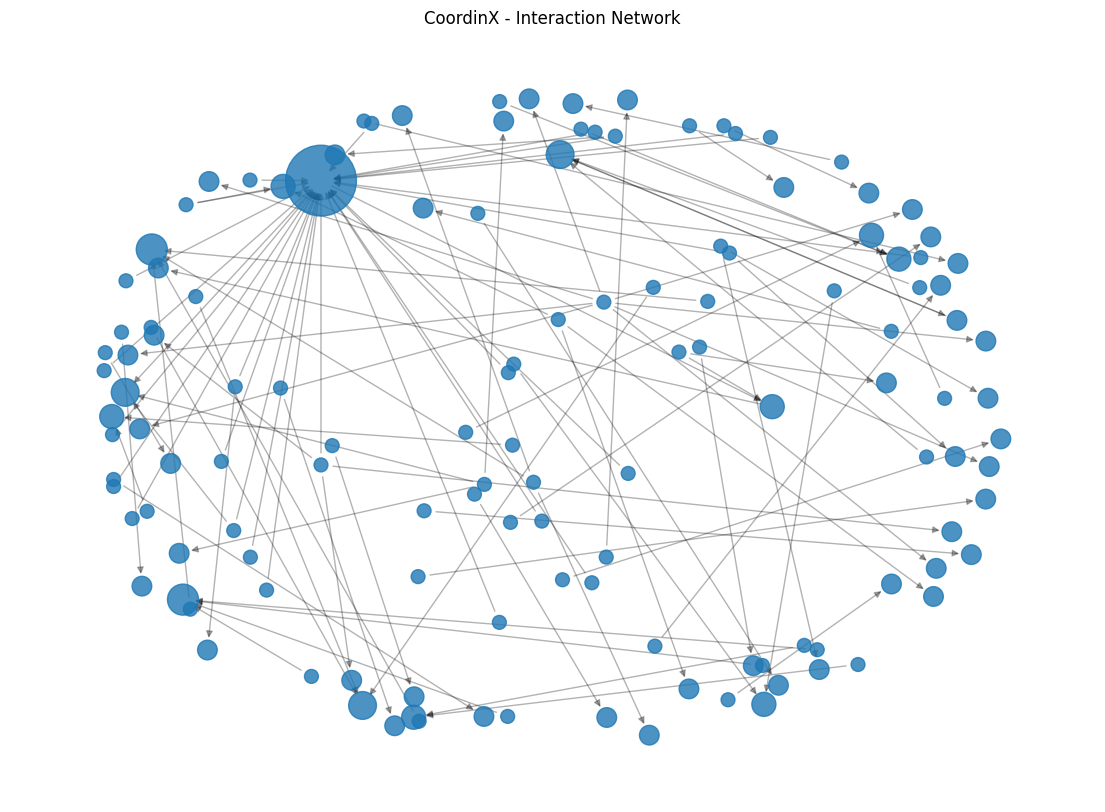

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

node_sizes = [
    100 + (G.in_degree(n) * 100)
    for n in G.nodes()
]

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    alpha=0.8
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    alpha=0.3,
    arrowsize=10
)

plt.title("CoordinX - Interaction Network")
plt.axis("off")
plt.show()

In [ ]:
components = list(nx.weakly_connected_components(G))

component_data = []

for i, component in enumerate(components, start=1):
    subgraph = G.subgraph(component)

    component_data.append({
        "component_id": i,
        "number_of_accounts": len(component),
        "number_of_edges": subgraph.number_of_edges(),
        "accounts": [
            username_map.get(node, node)
            for node in component
        ]
    })

components_df = pd.DataFrame(component_data)

components_df = components_df.sort_values(
    "number_of_accounts",
    ascending=False
)

display(components_df)

,component_id,number_of_accounts,number_of_edges,accounts
2,3,44,44,"[sananiiie, heniunique, QueenOfHeaven30, seijisuzuki6, Babyypinkeuu, kimdkoyoung, apricotleila, digiccams, wargamengamati, kiiibiland, Yukiosenasan, pinkeaasy, bebekhermes, blurryall, pvousmrvoyez, SalmaAdelia15, mwduyt, fillilabs, shiredora_, gimdong42827180, crasspeexi, SalingJagaWarga, aii_yayaya, kamarlintang, kurmasalak, bangherwin, windahbaruada, _linzykim, whiterosestea, laniintoyou_, 0ceankym, mamadkopling, BBCWorld, PocongGaib, _pierrehic, oqforwhat, vier4x4, KJohnwh, just_view_point, 1st_taherianz, RanuKala_, rockstarjjutin, mjamiebr, ilccue]"
30,31,9,8,"[cariaeosa, konoholicx, recehsjaa, ccaramelh2h, beautales_, senogp, akudanteh, fiolowee, bersuwara_]"
1,2,7,6,"[SarSapiii, Dubidamskii, chrngelique, indrianigunawan, AiNuraenij0, InFebriyan128, walhinasional]"
3,4,5,4,"[Boneheadsbanks, mariesbasee_, onemonstiez, zzepphyr, jenostalker]"
17,18,4,3,"[skylov3ly, kimchigyus, sowbeyyi, onyourremm02_]"
14,15,4,4,"[meowtinns, kyuurieq, theaa0sj, martinedwardspk]"
6,7,3,2,"[ABjodohComeback, HanzKey70, RikeSants]"
12,13,3,2,"[nndoweirs, eomjjuberry, mgenfox]"
16,17,3,2,"[shingibangi1317, sakuyasmom, luv_channa]"
22,23,3,2,"[Evelynfwpe, sasusakuinfo_id, uchiharere]"


In [ ]:
print("Jumlah kelompok:", len(components_df))
print("Kelompok terbesar:",
      components_df["number_of_accounts"].max())
print("Kelompok terkecil:",
      components_df["number_of_accounts"].min())

print("\nDistribusi ukuran kelompok:")
display(
    components_df["number_of_accounts"].value_counts()
    .sort_index()
)

Jumlah kelompok: 32
Kelompok terbesar: 44
Kelompok terkecil: 2

Distribusi ukuran kelompok:


,count
number_of_accounts,
2,20
3,6
4,2
5,1
7,1
9,1
44,1


In [ ]:
largest_component_id = components_df.iloc[0]["component_id"]

largest_component = components_df[
    components_df["component_id"] == largest_component_id
].iloc[0]

print("Component ID:", largest_component_id)
print("Jumlah akun:", largest_component["number_of_accounts"])
print("Jumlah edge:", largest_component["number_of_edges"])

display(pd.DataFrame({
    "username": largest_component["accounts"]
}))

Component ID: 3
Jumlah akun: 44
Jumlah edge: 44


,username
0,sananiiie
1,heniunique
2,QueenOfHeaven30
3,seijisuzuki6
4,Babyypinkeuu
5,kimdkoyoung
6,apricotleila
7,digiccams
8,wargamengamati
9,kiiibiland


Jumlah akun: 44
Jumlah edge: 44


,account_id,target_account_id,relation_type,interaction_count,source_username,target_username
74,2078714133990821888,152858346,quote,2,Babyypinkeuu,whiterosestea
34,1539563817549541377,2078714133990821888,quote,2,mwduyt,Babyypinkeuu
2,1133400562559475712,2078714133990821888,quote,1,mamadkopling,Babyypinkeuu
5,1312063032483180545,1107620514,reply,1,KJohnwh,heniunique
8,1316901689295663105,2078714133990821888,quote,1,seijisuzuki6,Babyypinkeuu
9,1325042507340677120,2078714133990821888,reply,1,laniintoyou_,Babyypinkeuu
11,1363774276688515076,2078714133990821888,reply,1,pvousmrvoyez,Babyypinkeuu
13,1399099485783924738,2052806389962350592,quote,1,Yukiosenasan,SalingJagaWarga
14,1399099485783924738,2078714133990821888,quote,1,Yukiosenasan,Babyypinkeuu
16,1419100742296608772,2078714133990821888,reply,1,fillilabs,Babyypinkeuu


,account_id,username,in_degree,out_degree,betweenness
5,2078714133990821888,Babyypinkeuu,25,2,0.040975
33,87500011,PocongGaib,3,0,0.000000
29,152858346,whiterosestea,2,1,0.014950
22,2052806389962350592,SalingJagaWarga,2,0,0.000000
1,1107620514,heniunique,1,0,0.000000
2,1913150241379086336,QueenOfHeaven30,1,0,0.000000
9,1265529982752882688,wargamengamati,1,0,0.000000
13,1754069930260172800,bebekhermes,1,0,0.000000
19,1022219592821698561,shiredora_,1,0,0.000000
24,761109964555378688,kamarlintang,1,0,0.000000


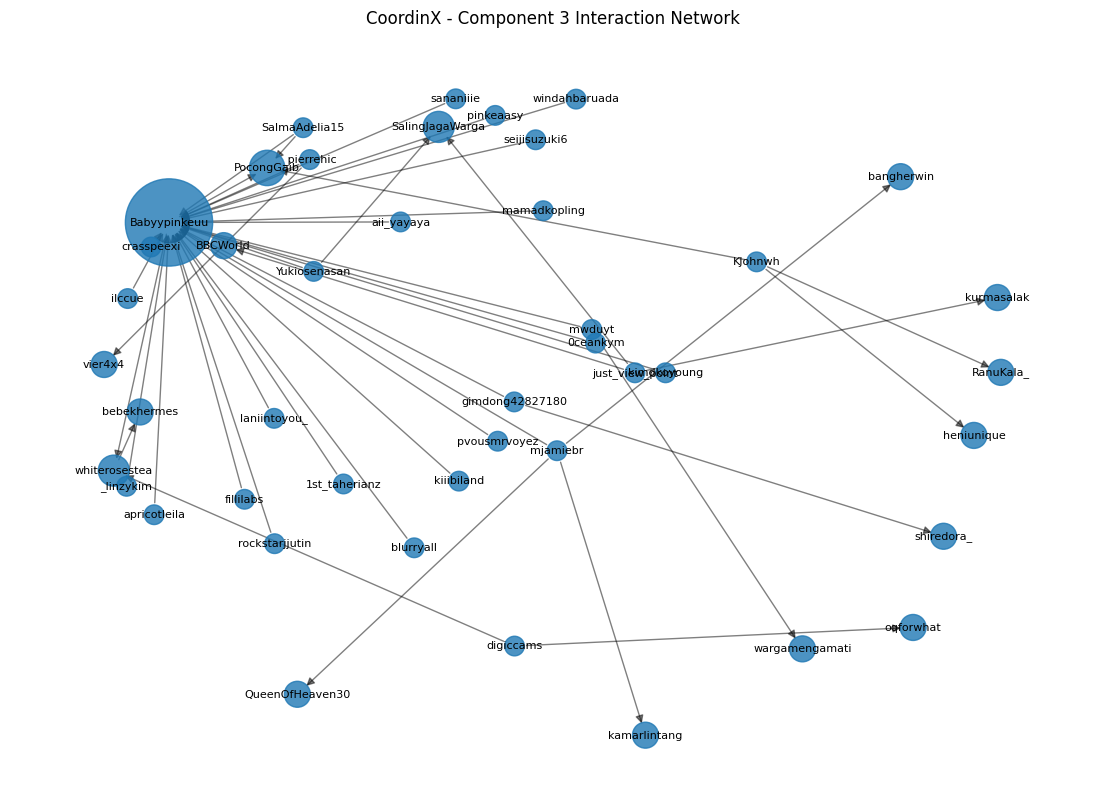

In [ ]:
component_3 = set(components[2])
component_3_edges = interaction_graph_edges[
    interaction_graph_edges["account_id"].isin(component_3)
    & interaction_graph_edges["target_account_id"].isin(component_3)
].copy()

print("Jumlah akun:", len(component_3))
print("Jumlah edge:", len(component_3_edges))

display(
    component_3_edges.sort_values(
        "interaction_count",
        ascending=False
    )
)

G3 = G.subgraph(component_3).copy()

component_centrality = pd.DataFrame({
    "account_id": list(G3.nodes()),
    "username": [
        username_map.get(node, node)
        for node in G3.nodes()
    ],
    "in_degree": [
        G3.in_degree(node)
        for node in G3.nodes()
    ],
    "out_degree": [
        G3.out_degree(node)
        for node in G3.nodes()
    ],
    "betweenness": list(
        nx.betweenness_centrality(G3).values()
    )
})

display(
    component_centrality.sort_values(
        ["in_degree", "out_degree"],
        ascending=False
    ).head(15)
)

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

pos3 = nx.spring_layout(
    G3,
    seed=42,
    k=0.8
)

node_sizes = [
    200 + G3.in_degree(n) * 150
    for n in G3.nodes()
]

nx.draw_networkx_nodes(
    G3,
    pos3,
    node_size=node_sizes,
    alpha=0.8
)

nx.draw_networkx_edges(
    G3,
    pos3,
    arrows=True,
    alpha=0.5,
    arrowsize=12
)

labels = {
    node: username_map.get(node, node)
    for node in G3.nodes()
}

nx.draw_networkx_labels(
    G3,
    pos3,
    labels=labels,
    font_size=8
)

plt.title("CoordinX - Component 3 Interaction Network")
plt.axis("off")
plt.show()

Node sebelum: 44
Node sesudah: 43
Edge sebelum: 44
Edge sesudah: 17
Connected components sebelum: 1
Connected components sesudah: 26
Ukuran komponen setelah Babyypinkeuu dihapus:
[5, 5, 4, 4, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


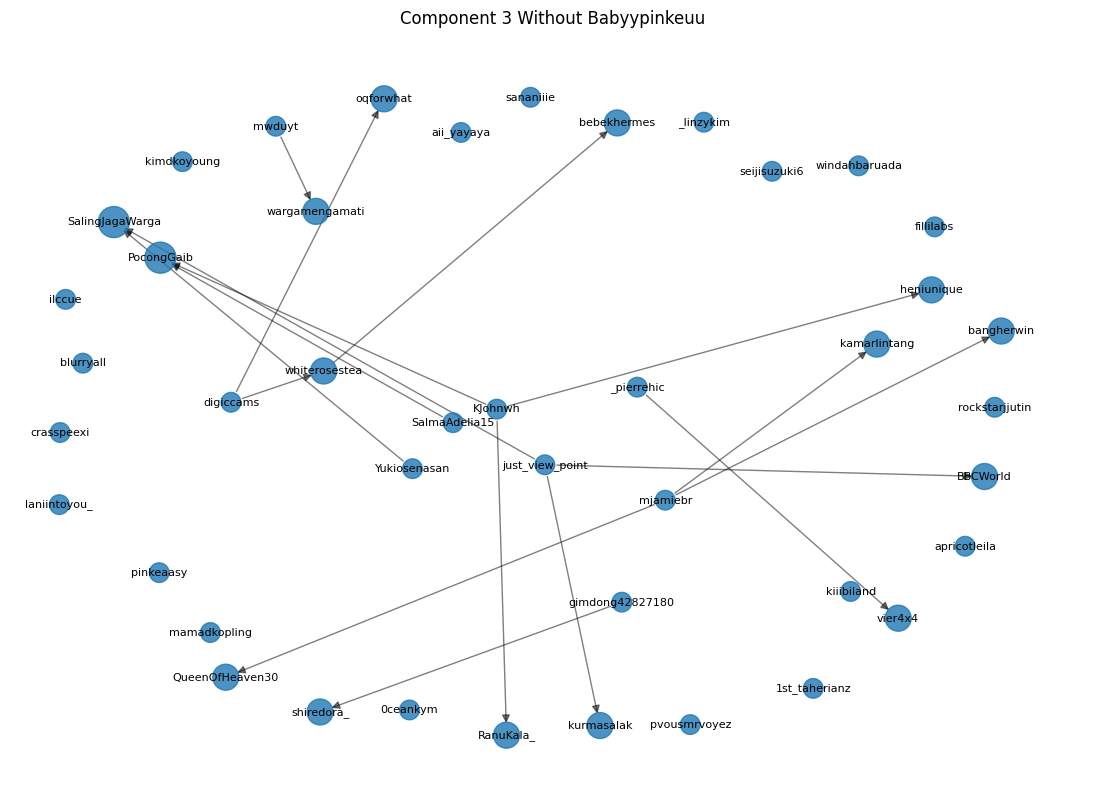

In [ ]:
G3_without_hub = G3.copy()

hub_id = "2078714133990821888"

G3_without_hub.remove_node(hub_id)

remaining_components = list(
    nx.weakly_connected_components(G3_without_hub)
)

print("Node sebelum:", G3.number_of_nodes())
print("Node sesudah:", G3_without_hub.number_of_nodes())

print("Edge sebelum:", G3.number_of_edges())
print("Edge sesudah:", G3_without_hub.number_of_edges())

print(
    "Connected components sebelum:",
    nx.number_weakly_connected_components(G3)
)

print(
    "Connected components sesudah:",
    len(remaining_components)
)

remaining_component_sizes = sorted(
    [len(c) for c in remaining_components],
    reverse=True
)

print("Ukuran komponen setelah Babyypinkeuu dihapus:")
print(remaining_component_sizes)

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G3_without_hub,
    seed=42,
    k=0.8
)

node_sizes = [
    200 + G3_without_hub.in_degree(n) * 150
    for n in G3_without_hub.nodes()
]

nx.draw_networkx_nodes(
    G3_without_hub,
    pos,
    node_size=node_sizes,
    alpha=0.8
)

nx.draw_networkx_edges(
    G3_without_hub,
    pos,
    arrows=True,
    alpha=0.5,
    arrowsize=12
)

labels = {
    node: username_map.get(node, node)
    for node in G3_without_hub.nodes()
}

nx.draw_networkx_labels(
    G3_without_hub,
    pos,
    labels=labels,
    font_size=8
)

plt.title("Component 3 Without Babyypinkeuu")
plt.axis("off")
plt.show()

In [ ]:
G3_undirected = G3.to_undirected()

articulation_nodes = list(
    nx.articulation_points(G3_undirected)
)

print("Jumlah articulation points:", len(articulation_nodes))

for node in articulation_nodes:
    print(username_map.get(node, node))

removal_results = []

for node in G3.nodes():

    temp_graph = G3.copy()
    temp_graph.remove_node(node)

    components_after = list(
        nx.weakly_connected_components(temp_graph)
    )

    sizes = sorted(
        [len(c) for c in components_after],
        reverse=True
    )

    removal_results.append({
        "username": username_map.get(node, node),
        "in_degree": G3.in_degree(node),
        "out_degree": G3.out_degree(node),
        "components_after": len(components_after),
        "largest_component_after": max(sizes) if sizes else 0
    })

removal_df = pd.DataFrame(removal_results)

display(
    removal_df.sort_values(
        ["components_after", "largest_component_after"],
        ascending=[False, True]
    ).head(15)
)

Jumlah articulation points: 12
Babyypinkeuu
digiccams
whiterosestea
KJohnwh
PocongGaib
just_view_point
SalingJagaWarga
Yukiosenasan
mwduyt
gimdong42827180
_pierrehic
mjamiebr


,username,in_degree,out_degree,components_after,largest_component_after
5,Babyypinkeuu,25,2,26,5
42,mjamiebr,0,4,4,40
29,whiterosestea,2,1,3,40
37,KJohnwh,0,3,3,41
38,just_view_point,0,3,3,41
11,Yukiosenasan,0,2,2,39
22,SalingJagaWarga,2,0,2,40
33,PocongGaib,3,0,2,40
8,digiccams,0,2,2,42
17,mwduyt,0,2,2,42


In [ ]:
G3_undirected = G3.to_undirected()

articulation_nodes = set(
    nx.articulation_points(G3_undirected)
)

betweenness = nx.betweenness_centrality(
    G3_undirected
)
component_size_map = {}

for component in nx.connected_components(G3_undirected):
    for node in component:
        component_size_map[node] = len(component)
removal_lookup = removal_df.set_index("username")

feature_rows = []

for node in G3.nodes():

    username = username_map.get(node, node)

    removal_info = removal_lookup.loc[username]

    feature_rows.append({
        "account_id": node,
        "username": username,

        "in_degree": G3.in_degree(node),
        "out_degree": G3.out_degree(node),
        "total_degree": (
            G3.in_degree(node) + G3.out_degree(node)
        ),

        "betweenness": betweenness[node],
        "is_articulation": int(node in articulation_nodes),

        "component_size": component_size_map[node],

        "removal_components": int(
            removal_info["components_after"]
        ),

        "largest_component_after": int(
            removal_info["largest_component_after"]
        )
    })

structural_features = pd.DataFrame(feature_rows)

display(
    structural_features.sort_values(
        "in_degree",
        ascending=False
    ).head(15)
)

structural_features.to_csv(
    "component_3_structural_features.csv",
    index=False
)

print("Structural features berhasil disimpan.")

,account_id,username,in_degree,out_degree,total_degree,betweenness,is_articulation,component_size,removal_components,largest_component_after
5,2078714133990821888,Babyypinkeuu,25,2,27,0.961240,1,44,26,5
33,87500011,PocongGaib,3,0,3,0.132890,1,44,2,40
22,2052806389962350592,SalingJagaWarga,2,0,2,0.132890,1,44,2,40
29,152858346,whiterosestea,2,1,3,0.135105,1,44,3,40
19,1022219592821698561,shiredora_,1,0,1,0.000000,0,44,1,43
26,1267940786991099905,bangherwin,1,0,1,0.000000,0,44,1,43
25,3007283059,kurmasalak,1,0,1,0.000000,0,44,1,43
24,761109964555378688,kamarlintang,1,0,1,0.000000,0,44,1,43
13,1754069930260172800,bebekhermes,1,0,1,0.000000,0,44,1,43
1,1107620514,heniunique,1,0,1,0.000000,0,44,1,43


Structural features berhasil disimpan.


In [ ]:
G_undirected = G.to_undirected()

all_articulation = set(
    nx.articulation_points(G_undirected)
)

all_betweenness = nx.betweenness_centrality(
    G_undirected,
    normalized=True
)

component_size_map = {}

for component in nx.connected_components(G_undirected):
    for node in component:
        component_size_map[node] = len(component)

all_structural_rows = []

for node in G.nodes():

    all_structural_rows.append({
        "account_id": node,
        "username": username_map.get(node, node),

        "in_degree": G.in_degree(node),
        "out_degree": G.out_degree(node),
        "total_degree": (
            G.in_degree(node) + G.out_degree(node)
        ),

        "undirected_betweenness": all_betweenness[node],

        "is_articulation": int(
            node in all_articulation
        ),

        "component_size": component_size_map[node]
    })

all_structural_features = pd.DataFrame(
    all_structural_rows
)

display(
    all_structural_features.sort_values(
        "in_degree",
        ascending=False
    ).head(20)
)

print("Total akun:", len(all_structural_features))
print(
    "Total articulation points:",
    all_structural_features["is_articulation"].sum()
)

print("\nDistribusi component size:")
display(
    all_structural_features["component_size"]
    .value_counts()
    .sort_index()
)

all_structural_features.to_csv(
    "all_accounts_structural_features.csv",
    index=False
)

print("Berhasil menyimpan structural features seluruh akun.")

,account_id,username,in_degree,out_degree,total_degree,undirected_betweenness,is_articulation,component_size
5,2078714133990821888,Babyypinkeuu,25,2,27,0.103518,1,44
3,67595121,InFebriyan128,4,0,4,0.001431,1,7
7,1885318915498401796,jenostalker,4,0,4,0.000716,1,5
53,2061981027967590400,martinedwardspk,3,1,4,0.000358,1,4
61,1615580516874596352,kimchigyus,3,0,3,0.000358,1,4
13,87500011,PocongGaib,3,0,3,0.014311,1,44
1,2051689194825920513,komisarisnetzen,2,0,2,0.000119,1,3
43,1439266381044674565,nndoweirs,2,0,2,0.000119,1,3
38,1734385427635945472,earlycahyax,2,0,2,0.000119,1,3
22,2052806389962350592,SalingJagaWarga,2,0,2,0.014311,1,44


Total akun: 131
Total articulation points: 24

Distribusi component size:


,count
component_size,
2,40
3,18
4,8
5,5
7,7
9,9
44,44


Berhasil menyimpan structural features seluruh akun.


In [ ]:
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    errors="coerce",
    utc=True
)

print("Waktu paling awal:")
print(df_clean["date"].min())

print("\nWaktu paling akhir:")
print(df_clean["date"].max())

print("\nTimestamp kosong:")
print(df_clean["date"].isna().sum())

daily_posts = (
    df_clean
    .dropna(subset=["date"])
    .assign(day=lambda x: x["date"].dt.date)
    .groupby("day")
    .size()
)

display(daily_posts)

Waktu paling awal:
2026-10-05 16:18:44+00:00

Waktu paling akhir:
2026-11-04 11:38:20+00:00

Timestamp kosong:
0


,0
day,
2026-10-05,1
2026-10-06,4
2026-10-07,4
2026-10-08,9
2026-10-09,11
2026-10-10,17
2026-10-11,23
2026-10-12,23
2026-10-13,20


,total_posts
day,
2026-10-05,1
2026-10-06,4
2026-10-07,4
2026-10-08,9
2026-10-09,11
2026-10-10,17
2026-10-11,23
2026-10-12,23
2026-10-13,20


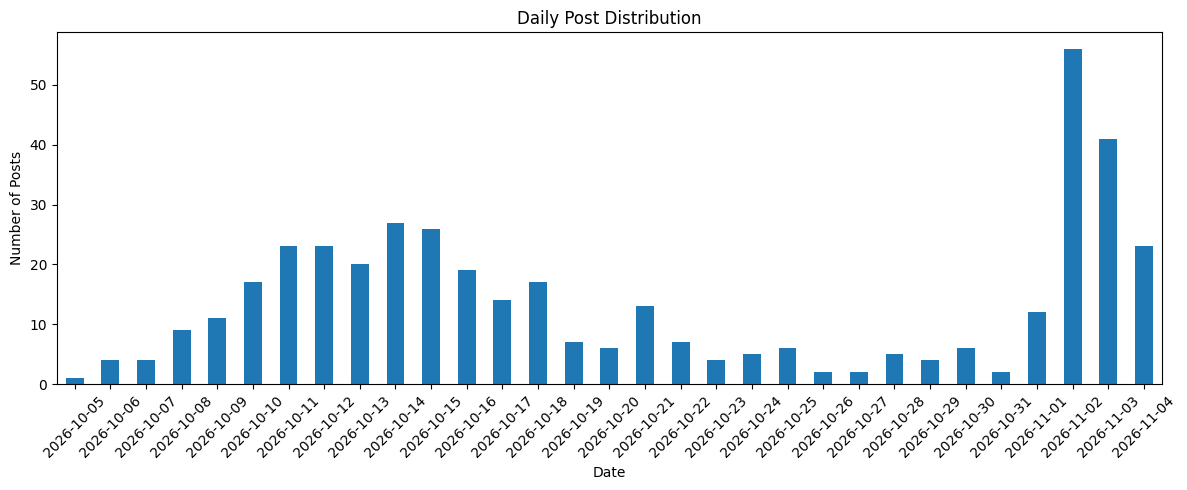

,total_posts
date,
0,21
1,31
2,18
3,21
4,14
5,20
6,16
7,19
8,23


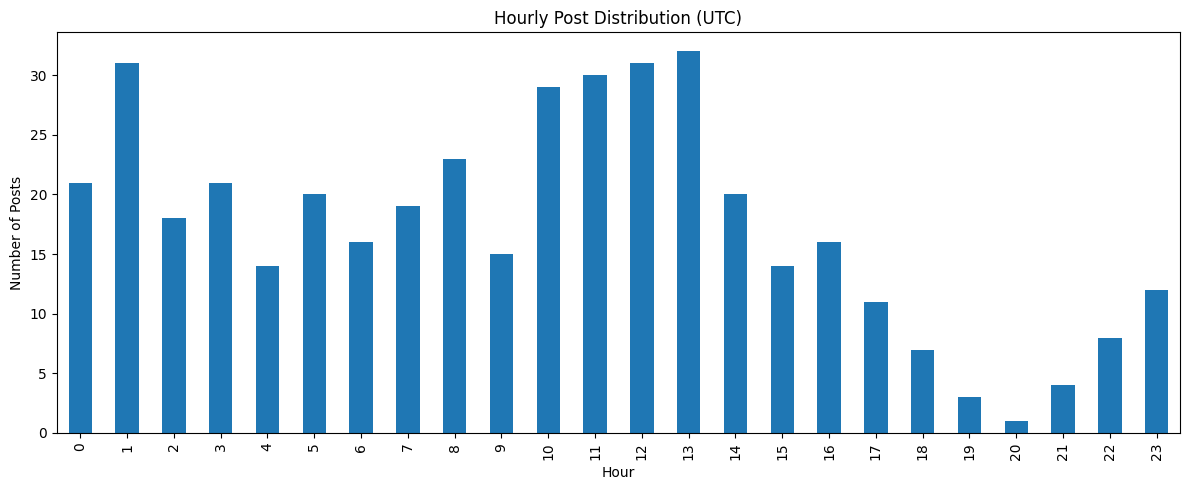

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

daily_posts = (
    df_clean
    .dropna(subset=["date"])
    .assign(day=lambda x: x["date"].dt.date)
    .groupby("day")
    .size()
    .sort_index()
)

display(
    daily_posts.rename("total_posts").to_frame()
)

plt.figure(figsize=(12, 5))
daily_posts.plot(kind="bar")

plt.title("Daily Post Distribution")
plt.xlabel("Date")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

hourly_posts = (
    df_clean
    .dropna(subset=["date"])
    .groupby(df_clean["date"].dt.hour)
    .size()
)

hourly_posts = hourly_posts.reindex(
    range(24),
    fill_value=0
)

display(
    hourly_posts.rename("total_posts").to_frame()
)

plt.figure(figsize=(12, 5))
hourly_posts.plot(kind="bar")

plt.title("Hourly Post Distribution (UTC)")
plt.xlabel("Hour")
plt.ylabel("Number of Posts")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

In [ ]:
temporal_data = df_clean.dropna(
    subset=["account_id", "date"]
).copy()

temporal_data = temporal_data.sort_values(
    ["account_id", "date"]
)
temporal_data["time_gap_minutes"] = (
    temporal_data
    .groupby("account_id")["date"]
    .diff()
    .dt.total_seconds() / 60
)
temporal_features = (
    temporal_data
    .groupby("account_id")
    .agg(
        total_posts=("post_id", "count"),
        first_post=("date", "min"),
        last_post=("date", "max"),
        avg_time_gap_minutes=("time_gap_minutes", "mean"),
        std_time_gap_minutes=("time_gap_minutes", "std"),
        min_time_gap_minutes=("time_gap_minutes", "min")
    )
    .reset_index()
)
active_days = (
    temporal_data
    .assign(day=temporal_data["date"].dt.date)
    .groupby("account_id")["day"]
    .nunique()
    .reset_index(name="active_days")
)

temporal_features = temporal_features.merge(
    active_days,
    on="account_id",
    how="left"
)
temporal_features["posts_per_day"] = (
    temporal_features["total_posts"] /
    temporal_features["active_days"]
)
display(
    temporal_features.sort_values(
        "total_posts",
        ascending=False
    ).head(20)
)

,account_id,total_posts,first_post,last_post,avg_time_gap_minutes,std_time_gap_minutes,min_time_gap_minutes,active_days,posts_per_day
204,2078714133990821888,23,2026-10-17 02:42:00+00:00,2026-11-04 07:27:39+00:00,1191.165909,3767.820831,1.383333,7,3.285714
140,1885318915498401796,22,2026-10-06 00:41:49+00:00,2026-10-27 13:42:15+00:00,1477.163492,1697.861230,82.466667,15,1.466667
108,1717201992567939072,13,2026-10-14 13:02:54+00:00,2026-10-26 13:59:19+00:00,1444.701389,1462.355863,2.416667,8,1.625000
188,2051689194825920513,11,2026-10-08 13:14:54+00:00,2026-10-15 14:48:16+00:00,1017.336667,1122.530061,76.216667,6,1.833333
243,903456043304239104,9,2026-11-02 10:12:44+00:00,2026-11-04 10:10:37+00:00,359.735417,431.928897,3.183333,3,3.000000
68,1518351214378815488,8,2026-10-15 01:37:08+00:00,2026-10-21 08:00:01+00:00,1288.983333,2632.174058,13.783333,3,2.666667
91,160824275,7,2026-10-10 16:47:12+00:00,2026-11-03 16:19:13+00:00,5755.336111,8069.518593,28.033333,5,1.400000
227,300681205,7,2026-10-08 05:39:03+00:00,2026-10-13 00:25:29+00:00,1147.738889,1766.705082,61.450000,4,1.750000
143,1901636124105424896,5,2026-10-11 10:35:46+00:00,2026-10-16 07:58:23+00:00,1760.654167,1053.569763,446.383333,4,1.250000
139,1884148869686300672,5,2026-11-03 01:16:01+00:00,2026-11-03 16:55:49+00:00,234.950000,468.244857,0.300000,1,5.000000


In [ ]:
  hourly_account_activity = (
    temporal_data
    .set_index("date")
    .groupby("account_id")
    .resample("1h")
    .size()
    .reset_index(name="posts_per_hour")
)

display(
    hourly_account_activity
    .sort_values("posts_per_hour", ascending=False)
    .head(20)
)

,account_id,date,posts_per_hour
3075,1884148869686300672,2026-11-03 16:00:00+00:00,4
2723,1757254673596383232,2026-11-03 03:00:00+00:00,3
417,1402448352885710848,2026-11-03 01:00:00+00:00,3
678,1518351214378815488,2026-10-15 15:00:00+00:00,2
503,1469266878568665088,2026-11-02 17:00:00+00:00,2
2341,1717201992567939072,2026-10-14 13:00:00+00:00,2
416,1399099485783924738,2026-11-02 11:00:00+00:00,2
4058,2033718778455031808,2026-11-02 09:00:00+00:00,2
2334,1645697437020098562,2026-11-02 17:00:00+00:00,2
5288,2078714133990821888,2026-11-02 00:00:00+00:00,2


In [ ]:
hourly_complete = []

for account_id, group in temporal_data.groupby("account_id"):

    account_hourly = (
        group.set_index("date")
        .resample("1h")
        .size()
    )

    account_hourly = account_hourly.asfreq("1h", fill_value=0)

    account_hourly = account_hourly.rename(
        "posts_per_hour"
    ).reset_index()

    account_hourly["account_id"] = account_id

    hourly_complete.append(account_hourly)

hourly_complete = pd.concat(
    hourly_complete,
    ignore_index=True
)

account_hourly_stats = (
    hourly_complete
    .groupby("account_id")
    .agg(
        mean_posts_per_hour=("posts_per_hour", "mean"),
        std_posts_per_hour=("posts_per_hour", "std"),
        max_posts_per_hour=("posts_per_hour", "max"),
        observed_hours=("posts_per_hour", "count")
    )
    .reset_index()
)

hourly_anomaly = hourly_complete.merge(
    account_hourly_stats,
    on="account_id",
    how="left"
)

hourly_anomaly["activity_zscore"] = (
    (hourly_anomaly["posts_per_hour"] -
     hourly_anomaly["mean_posts_per_hour"])
    / hourly_anomaly["std_posts_per_hour"]
)

display(
    hourly_anomaly
    .sort_values("activity_zscore", ascending=False)
    [[
        "account_id",
        "date",
        "posts_per_hour",
        "mean_posts_per_hour",
        "std_posts_per_hour",
        "activity_zscore"
    ]]
    .head(20)
)

,account_id,date,posts_per_hour,mean_posts_per_hour,std_posts_per_hour,activity_zscore
4566,2042231023405297664,2026-11-02 11:00:00+00:00,1,0.003953,0.062807,15.858814
4061,2042231023405297664,2026-10-12 10:00:00+00:00,1,0.003953,0.062807,15.858814
6032,67595121,2026-10-11 01:00:00+00:00,1,0.005495,0.073989,13.441298
6576,67595121,2026-11-02 17:00:00+00:00,1,0.005495,0.073989,13.441298
6031,67595121,2026-10-11 00:00:00+00:00,1,0.005495,0.073989,13.441298
5902,2328181406,2026-10-27 07:00:00+00:00,1,0.006550,0.080756,12.301850
5445,2328181406,2026-10-08 06:00:00+00:00,1,0.006550,0.080756,12.301850
5547,2328181406,2026-10-12 12:00:00+00:00,1,0.006550,0.080756,12.301850
210,1393950183596068869,2026-10-15 12:00:00+00:00,1,0.009756,0.098531,10.050118
414,1393950183596068869,2026-10-24 00:00:00+00:00,1,0.009756,0.098531,10.050118


In [ ]:
burst_candidates = (
    hourly_complete[
        hourly_complete["posts_per_hour"] >= 2
    ]
    .sort_values(
        "posts_per_hour",
        ascending=False
    )
)

display(
    burst_candidates[
        [
            "account_id",
            "date",
            "posts_per_hour"
        ]
    ].head(30)
)
burst_summary = (
    hourly_complete
    .groupby("account_id")
    .agg(
        total_posts=("posts_per_hour", "sum"),
        max_posts_per_hour=("posts_per_hour", "max"),
        hours_with_multiple_posts=(
            "posts_per_hour",
            lambda x: (x >= 2).sum()
        )
    )
    .reset_index()
)

display(
    burst_summary
    .sort_values(
        ["max_posts_per_hour", "hours_with_multiple_posts"],
        ascending=False
    )
    .head(20)
)

,account_id,date,posts_per_hour
3075,1884148869686300672,2026-11-03 16:00:00+00:00,4
417,1402448352885710848,2026-11-03 01:00:00+00:00,3
2723,1757254673596383232,2026-11-03 03:00:00+00:00,3
503,1469266878568665088,2026-11-02 17:00:00+00:00,2
678,1518351214378815488,2026-10-15 15:00:00+00:00,2
818,1521656155562713088,2026-11-03 14:00:00+00:00,2
2001,1624301340058062848,2026-11-02 18:00:00+00:00,2
1382,1539563817549541377,2026-11-02 09:00:00+00:00,2
2334,1645697437020098562,2026-11-02 17:00:00+00:00,2
2341,1717201992567939072,2026-10-14 13:00:00+00:00,2


,account_id,total_posts,max_posts_per_hour,hours_with_multiple_posts
139,1884148869686300672,5,4,1
47,1402448352885710848,3,3,1
119,1757254673596383232,3,3,1
204,2078714133990821888,23,2,8
243,903456043304239104,9,2,3
108,1717201992567939072,13,2,2
46,1399099485783924738,2,2,1
59,1469266878568665088,4,2,1
68,1518351214378815488,8,2,1
71,1521656155562713088,2,2,1


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv(
    "/content/standardized_data.csv",
    dtype={"post_id": "string", "account_id": "string"}
)

df_clean = df.drop_duplicates(
    subset=["post_id"],
    keep="first"
).copy()

df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    utc=True,
    errors="coerce"
)

posts_time = (
    df_clean[["post_id", "account_id", "date", "text"]]
    .dropna(subset=["account_id", "date"])
    .copy()
)

posts_time["date"] = pd.to_datetime(
    posts_time["date"],
    utc=True
)

posts_time["time_window"] = posts_time["date"].dt.floor("5min")

temporal_groups = (
    posts_time.groupby("time_window")
    .agg(
        total_posts=("post_id", "count"),
        unique_accounts=("account_id", "nunique"),
        account_ids=("account_id", lambda x: list(x.unique()))
    )
    .reset_index()
)

temporal_groups = (
    temporal_groups[
        temporal_groups["unique_accounts"] >= 2
    ]
    .sort_values(
        ["unique_accounts", "total_posts"],
        ascending=False
    )
    .reset_index(drop=True)
)

print("Jumlah kandidat temporal:", len(temporal_groups))

display(temporal_groups.head(15))

Jumlah kandidat temporal: 16


,time_window,total_posts,unique_accounts,account_ids
0,2026-11-03 01:15:00+00:00,5,3,"[1607386266324332545, 1884148869686300672, 140..."
1,2026-10-11 03:25:00+00:00,3,2,"[2085151865705246720, 2091157265772670976]"
2,2026-10-08 14:35:00+00:00,2,2,"[1247462449722212358, 2051689194825920513]"
3,2026-10-11 00:25:00+00:00,2,2,"[67595121, 2100471599283757056]"
4,2026-10-12 13:25:00+00:00,2,2,"[1411336349903245313, 1959115105809178626]"
5,2026-10-14 05:50:00+00:00,2,2,"[1588484682018041856, 2053164102302814210]"
6,2026-10-15 01:35:00+00:00,2,2,"[1518351214378815488, 2064671719001092096]"
7,2026-10-19 10:30:00+00:00,2,2,"[1159475566069731331, 908172930]"
8,2026-11-02 09:35:00+00:00,2,2,"[1539563817549541377, 2033718778455031808]"
9,2026-11-02 10:15:00+00:00,2,2,"[1267940786991099905, 903456043304239104]"


In [9]:
selected_windows = temporal_groups.head(15)["time_window"]

temporal_group_details = (
    posts_time[
        posts_time["time_window"].isin(selected_windows)
    ]
    .sort_values(["time_window", "date"])
)

display(
    temporal_group_details[
        ["time_window", "date", "account_id", "post_id", "text"]
    ].to_string(index=False)
)

'              time_window                      date          account_id             post_id                                                                                                                                                                                                                                                                                                                                                         text\n2026-10-08 14:35:00+00:00 2026-10-08 14:37:17+00:00 1247462449722212358 2108205092944204252                                                                                                                                                                                                                                         People in Jawa be like: "Hirup dalem2 asepnye dik Malay" when their Kalimantan friend literally berbumbungkan neraka\n2026-10-08 14:35:00+00:00 2026-10-08 14:39:59+00:00 2051689194825920513 2108205773474156649                        

In [10]:
target_window = pd.Timestamp("2026-11-03 01:15:00", tz="UTC")

target_posts = (
    posts_time[
        posts_time["time_window"] == target_window
    ]
    .sort_values("date")
)

for _, row in target_posts.iterrows():
    print("=" * 80)
    print("Account ID :", row["account_id"])
    print("Post ID    :", row["post_id"])
    print("Date       :", row["date"])
    print("Text       :")
    print(row["text"])
    print()

Account ID : 1402448352885710848
Post ID    : 2117425293325701274
Date       : 2026-11-03 01:15:04+00:00
Text       :
TETAP BERISIK 

#PRAYFORLAMPUNG
#PRAYFORSULAWESI
#PRAYFORKALIMANTAN
#PRAYFORSUMATERA
#PRAYFORACEH
#PRAYFORNTT
#PRAYFORNTB
#PRAYFORPAPUA
#PRAYFORINDONESIA
#AllEyesOnIndonesia 
#INDONESIASADAR 
#IndonesiaButuhOksigen 
#PMRNTHKNTL https://t.co/PHoCuH9lN5

Account ID : 1402448352885710848
Post ID    : 2117425365044076781
Date       : 2026-11-03 01:15:21+00:00
Text       :
#PRAYFORLAMPUNG
#PRAYFORSULAWESI
#PRAYFORKALIMANTAN
#PRAYFORSUMATERA
#PRAYFORACEH
#PRAYFORNTT
#PRAYFORNTB
#PRAYFORPAPUA
#PRAYFORINDONESIA
#AllEyesOnIndonesia 
#INDONESIASADAR 
#IndonesiaButuhOksigen 
#PMRNTHKNTL

Account ID : 1402448352885710848
Post ID    : 2117425417766445253
Date       : 2026-11-03 01:15:34+00:00
Text       :
#PRAYFORLAMPUNG
#PRAYFORSULAWESI
#PRAYFORKALIMANTAN
#PRAYFORSUMATERA
#PRAYFORACEH
#PRAYFORNTT
#PRAYFORNTB
#PRAYFORPAPUA
#PRAYFORINDONESIA
#AllEyesOnIndonesia 
#INDONESIASADAR 
#Ind

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from itertools import combinations
import pandas as pd

similarity_data = target_posts.copy().reset_index(drop=True)

similarity_data["text"] = similarity_data["text"].fillna("")

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

tfidf_matrix = vectorizer.fit_transform(similarity_data["text"])

similarity_matrix = cosine_similarity(tfidf_matrix)

similarity_results = []

for i, j in combinations(range(len(similarity_data)), 2):
    account_1 = similarity_data.loc[i, "account_id"]
    account_2 = similarity_data.loc[j, "account_id"]

    similarity_results.append({
        "account_1": account_1,
        "account_2": account_2,
        "post_1": similarity_data.loc[i, "post_id"],
        "post_2": similarity_data.loc[j, "post_id"],
        "same_account": account_1 == account_2,
        "similarity": similarity_matrix[i, j]
    })

similarity_results = pd.DataFrame(similarity_results)

cross_account_similarity = (
    similarity_results[
        similarity_results["same_account"] == False
    ]
    .sort_values("similarity", ascending=False)
    .reset_index(drop=True)
)

display(cross_account_similarity)

,account_1,account_2,post_1,post_2,same_account,similarity
0,1402448352885710848,1884148869686300672,2117425365044076781,2117425532879200327,False,1.000000
1,1402448352885710848,1884148869686300672,2117425417766445253,2117425532879200327,False,1.000000
2,1402448352885710848,1884148869686300672,2117425293325701274,2117425532879200327,False,0.665155
3,1402448352885710848,1607386266324332545,2117425293325701274,2117425774395638172,False,0.000000
4,1402448352885710848,1607386266324332545,2117425365044076781,2117425774395638172,False,0.000000
5,1402448352885710848,1607386266324332545,2117425417766445253,2117425774395638172,False,0.000000
6,1884148869686300672,1607386266324332545,2117425532879200327,2117425774395638172,False,0.000000


In [12]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from itertools import combinations

analysis_data = target_posts.copy().reset_index(drop=True)

def extract_body(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"#\w+", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

def extract_hashtags(text):
    return set(re.findall(r"#\w+", str(text).lower()))

analysis_data["body"] = analysis_data["text"].apply(extract_body)
analysis_data["hashtags"] = analysis_data["text"].apply(extract_hashtags)

body_vectorizer = TfidfVectorizer(ngram_range=(1, 2))
body_matrix = body_vectorizer.fit_transform(analysis_data["body"])
body_similarity = cosine_similarity(body_matrix)

results = []

for i, j in combinations(range(len(analysis_data)), 2):
    row_a = analysis_data.iloc[i]
    row_b = analysis_data.iloc[j]

    if row_a["account_id"] == row_b["account_id"]:
        continue

    hashtags_a = row_a["hashtags"]
    hashtags_b = row_b["hashtags"]

    union = hashtags_a | hashtags_b
    intersection = hashtags_a & hashtags_b

    hashtag_jaccard = (
        len(intersection) / len(union)
        if union else 0
    )

    results.append({
        "account_1": row_a["account_id"],
        "account_2": row_b["account_id"],
        "post_1": row_a["post_id"],
        "post_2": row_b["post_id"],
        "body_similarity": body_similarity[i, j],
        "hashtag_jaccard": hashtag_jaccard,
        "shared_hashtags": list(intersection)
    })

comparison_results = pd.DataFrame(results)

display(
    comparison_results.sort_values(
        "hashtag_jaccard",
        ascending=False
    )
)

,account_1,account_2,post_1,post_2,body_similarity,hashtag_jaccard,shared_hashtags
0,1402448352885710848,1884148869686300672,2117425293325701274,2117425532879200327,0.0,1.0,"[#alleyesonindonesia, #pmrnthkntl, #prayforkal..."
2,1402448352885710848,1884148869686300672,2117425365044076781,2117425532879200327,0.0,1.0,"[#alleyesonindonesia, #pmrnthkntl, #prayforkal..."
4,1402448352885710848,1884148869686300672,2117425417766445253,2117425532879200327,0.0,1.0,"[#alleyesonindonesia, #pmrnthkntl, #prayforkal..."
1,1402448352885710848,1607386266324332545,2117425293325701274,2117425774395638172,0.0,0.0,[]
3,1402448352885710848,1607386266324332545,2117425365044076781,2117425774395638172,0.0,0.0,[]
5,1402448352885710848,1607386266324332545,2117425417766445253,2117425774395638172,0.0,0.0,[]
6,1884148869686300672,1607386266324332545,2117425532879200327,2117425774395638172,0.0,0.0,[]


In [14]:
import re
import numpy as np
import pandas as pd
from itertools import combinations
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

coord_data = posts_time.copy().reset_index(drop=True)
coord_data["date"] = pd.to_datetime(coord_data["date"], utc=True)

def extract_body(text):
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"#\w+", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

def extract_hashtags(text):
    return set(re.findall(r"#\w+", str(text).lower()))

coord_data["body"] = coord_data["text"].apply(extract_body)
coord_data["hashtags"] = coord_data["text"].apply(extract_hashtags)

# TF-IDF seluruh teks
text_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1)
text_matrix = text_vec.fit_transform(coord_data["text"].fillna(""))

# TF-IDF body (hanya yang tidak kosong)
valid_body_idx = coord_data.index[coord_data["body"].str.len() > 0]
body_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1)
body_matrix = body_vec.fit_transform(coord_data.loc[valid_body_idx, "body"])
body_pos = {idx: pos for pos, idx in enumerate(valid_body_idx)}

def jaccard(a, b):
    if not a and not b:
        return np.nan  # keduanya tanpa hashtag -> tidak bisa dinilai
    return len(a & b) / len(a | b)

# Kandidat: time_window dengan >= 2 akun unik
win_acc = coord_data.groupby("time_window")["account_id"].nunique()
candidate_windows = win_acc[win_acc >= 2].index

rows = []
for w in candidate_windows:
    grp = coord_data[coord_data["time_window"] == w]
    for i, j in combinations(grp.index, 2):
        if coord_data.at[i, "account_id"] == coord_data.at[j, "account_id"]:
            continue  # hanya pasangan lintas akun
        gap = abs((coord_data.at[i, "date"] - coord_data.at[j, "date"]).total_seconds())
        full_sim = cosine_similarity(text_matrix[i], text_matrix[j])[0, 0]
        if i in body_pos and j in body_pos:
            body_sim = cosine_similarity(body_matrix[body_pos[i]], body_matrix[body_pos[j]])[0, 0]
        else:
            body_sim = np.nan  # salah satu/kedua body kosong
        rows.append({
            "time_window": w,
            "account_a": coord_data.at[i, "account_id"],
            "account_b": coord_data.at[j, "account_id"],
            "gap_sec": gap,
            "full_text_sim": round(full_sim, 3),
            "body_sim": round(body_sim, 3) if pd.notna(body_sim) else np.nan,
            "hashtag_sim": jaccard(coord_data.at[i, "hashtags"], coord_data.at[j, "hashtags"]),
            "body_a": coord_data.at[i, "body"][:50],
            "body_b": coord_data.at[j, "body"][:50],
        })

pair_df = pd.DataFrame(rows)
print("Window kandidat :", len(candidate_windows))
print("Pasangan lintas akun:", len(pair_df))

if len(pair_df):
    print("Hashtag identik (=1.0):", (pair_df["hashtag_sim"] == 1.0).sum())
    print("Body sim >= 0.5       :", (pair_df["body_sim"] >= 0.5).sum())
    print("Body kosong/NaN       :", pair_df["body_sim"].isna().sum())
    top = pair_df.sort_values(
        ["hashtag_sim", "body_sim", "gap_sec"],
        ascending=[False, False, True],
        na_position="last"
    ).head(20)
    print(top.to_string(index=False))

Window kandidat : 16
Pasangan lintas akun: 23
Hashtag identik (=1.0): 4
Body sim >= 0.5       : 0
Body kosong/NaN       : 11
              time_window           account_a           account_b  gap_sec  full_text_sim  body_sim  hashtag_sim                                             body_a                                             body_b
2026-11-03 01:15:00+00:00 1884148869686300672 1402448352885710848     27.0          1.000       NaN     1.000000                                                                                                      
2026-11-03 01:15:00+00:00 1884148869686300672 1402448352885710848     40.0          1.000       NaN     1.000000                                                                                                      
2026-11-02 11:25:00+00:00 1399099485783924738 1235704866565054464     46.0          0.541       NaN     1.000000                                                                                       wowo ngebtoottt
2026-11-03 01:1

In [15]:
from collections import Counter

N = len(coord_data)
tag_df = Counter(tag for s in coord_data["hashtags"] for tag in s)

def tags_of(acc, w):
    sub = coord_data[(coord_data["account_id"] == acc) & (coord_data["time_window"] == w)]
    s = set()
    for h in sub["hashtags"]:
        s |= h
    return s

cand = pair_df[pair_df["hashtag_sim"] >= 0.8]
for _, r in cand.iterrows():
    common = tags_of(r["account_a"], r["time_window"]) & tags_of(r["account_b"], r["time_window"])
    freq = sorted((tag_df[t], t) for t in common)
    print(r["time_window"], r["account_a"][-6:], r["account_b"][-6:],
          "| n_common:", len(common),
          "| rarest:", [(t, f) for f, t in freq[:3]],
          "| median_df%:", round(100 * np.median([f for f, _ in freq]) / N, 1) if freq else None)

# Agregasi ke level pasangan akun (tidak lagi per post)
pair_df["acc_pair"] = pair_df.apply(
    lambda r: tuple(sorted([r["account_a"], r["account_b"]])), axis=1)
acc_pairs = pair_df.groupby("acc_pair").agg(
    n_post_pairs=("gap_sec", "size"),
    n_windows=("time_window", "nunique"),
    min_gap=("gap_sec", "min"),
    max_hashtag_sim=("hashtag_sim", "max"),
    max_full_sim=("full_text_sim", "max"),
).sort_values(["n_windows", "n_post_pairs"], ascending=False)
print(acc_pairs.head(15).to_string())

2026-11-02 09:35:00+00:00 541377 031808 | n_common: 12 | rarest: [('#indonesiasadar', 106), ('#indonesiabutuhoksigen', 108), ('#prayforntb', 151)] | median_df%: 37.7
2026-11-02 11:25:00+00:00 924738 054464 | n_common: 13 | rarest: [('#pmrnthkntl', 70), ('#indonesiasadar', 106), ('#indonesiabutuhoksigen', 108)] | median_df%: 37.5
2026-11-02 15:10:00+00:00 341440 821888 | n_common: 13 | rarest: [('#pmrnthkntl', 70), ('#indonesiasadar', 106), ('#indonesiabutuhoksigen', 108)] | median_df%: 37.5
2026-11-02 18:40:00+00:00 062848 237632 | n_common: 12 | rarest: [('#indonesiasadar', 106), ('#indonesiabutuhoksigen', 108), ('#prayforntb', 151)] | median_df%: 37.7
2026-11-03 01:15:00+00:00 300672 710848 | n_common: 13 | rarest: [('#pmrnthkntl', 70), ('#indonesiasadar', 106), ('#indonesiabutuhoksigen', 108)] | median_df%: 37.5
2026-11-03 01:15:00+00:00 300672 710848 | n_common: 13 | rarest: [('#pmrnthkntl', 70), ('#indonesiasadar', 106), ('#indonesiabutuhoksigen', 108)] | median_df%: 37.5
2026-11-

In [16]:
import numpy as np

N = len(coord_data)
idf = {t: np.log(N / f) for t, f in tag_df.items()}

def w_tag_sim(a, b):
    inter = a & b
    union = a | b
    if not union:
        return np.nan
    return sum(idf[t] for t in inter) / sum(idf[t] for t in union)

def tags_union(acc, w):
    sub = coord_data[(coord_data["account_id"] == acc) & (coord_data["time_window"] == w)]
    s = set()
    for h in sub["hashtags"]:
        s |= h
    return s

pair_df["w_tag_sim"] = pair_df.apply(
    lambda r: w_tag_sim(tags_union(r["account_a"], r["time_window"]),
                        tags_union(r["account_b"], r["time_window"])), axis=1)

print(pair_df[["time_window", "gap_sec", "full_text_sim", "hashtag_sim", "w_tag_sim"]]
      .sort_values("w_tag_sim", ascending=False).head(15).to_string(index=False))

chk = coord_data[coord_data["account_id"].isin(["1539563817549541377", "2033718778455031808"])
                 & (coord_data["time_window"] == pd.Timestamp("2026-11-02 09:35:00+00:00"))]
print(chk[["date", "account_id", "text"]].to_string(index=False))

              time_window  gap_sec  full_text_sim  hashtag_sim  w_tag_sim
2026-11-03 01:15:00+00:00     27.0          1.000     1.000000   1.000000
2026-11-03 01:15:00+00:00     57.0          0.609     1.000000   1.000000
2026-11-02 11:25:00+00:00     46.0          0.541     1.000000   1.000000
2026-11-03 01:15:00+00:00     40.0          1.000     1.000000   1.000000
2026-11-02 09:35:00+00:00    134.0          0.927     0.923077   0.863870
2026-11-04 06:55:00+00:00    152.0          0.234     0.928571   0.710379
2026-11-02 15:10:00+00:00    204.0          0.131     0.928571   0.684629
2026-11-02 18:40:00+00:00      5.0          0.415     0.857143   0.591430
2026-11-03 11:25:00+00:00    173.0          0.014     0.133333   0.048133
2026-10-14 05:50:00+00:00    206.0          0.041     0.500000   0.032371
2026-10-19 10:30:00+00:00    110.0          0.004     0.142857   0.011163
2026-10-11 03:25:00+00:00     73.0          0.043     0.083333   0.007518
2026-10-11 03:25:00+00:00     62.0    

In [17]:
def tag_list(text):
    return re.findall(r"#\w+", str(text).lower())

def block_info(acc, w):
    sub = coord_data[(coord_data["account_id"] == acc) & (coord_data["time_window"] == w)]
    lists = [tag_list(t) for t in sub["text"]]
    longest = max(lists, key=len) if lists else []
    is_block = any(len(l) >= 8 and len(coord_data.loc[sub.index[k], "body"]) == 0
                   for k, l in enumerate(lists))
    return longest, is_block

feat = []
for _, r in pair_df.iterrows():
    la, ba = block_info(r["account_a"], r["time_window"])
    lb, bb = block_info(r["account_b"], r["time_window"])
    n = min(len(la), len(lb))
    same_order = (la[:n] == lb[:n]) if n >= 5 else np.nan
    feat.append({
        "n_tags_a": len(la),
        "n_tags_b": len(lb),
        "both_hashtag_block": ba and bb,
        "same_order": same_order,
    })

pair_feat = pd.concat([pair_df.reset_index(drop=True), pd.DataFrame(feat)], axis=1)

print("Keduanya blok hashtag :", pair_feat["both_hashtag_block"].sum())
print("Urutan identik        :", (pair_feat["same_order"] == True).sum())
print(pair_feat[["time_window", "gap_sec", "full_text_sim", "w_tag_sim",
                 "n_tags_a", "n_tags_b", "both_hashtag_block", "same_order"]]
      .sort_values(["both_hashtag_block", "w_tag_sim"], ascending=False)
      .head(15).to_string(index=False))

Keduanya blok hashtag : 4
Urutan identik        : 6
              time_window  gap_sec  full_text_sim  w_tag_sim  n_tags_a  n_tags_b  both_hashtag_block same_order
2026-11-03 01:15:00+00:00     27.0          1.000   1.000000        13        13                True       True
2026-11-03 01:15:00+00:00     40.0          1.000   1.000000        13        13                True       True
2026-11-03 01:15:00+00:00     57.0          0.609   1.000000        13        13                True       True
2026-11-02 09:35:00+00:00    134.0          0.927   0.863870        12        13                True       True
2026-11-02 11:25:00+00:00     46.0          0.541   1.000000        13        13               False       True
2026-11-04 06:55:00+00:00    152.0          0.234   0.710379        13        14               False       True
2026-11-02 15:10:00+00:00    204.0          0.131   0.684629        13        14               False      False
2026-11-02 18:40:00+00:00      5.0          0.415   

In [18]:
def tag_seq(text):
    return tuple(re.findall(r"#\w+", str(text).lower()))

coord_data["tag_seq"] = coord_data["text"].apply(tag_seq)
coord_data["n_tags"] = coord_data["tag_seq"].apply(len)
coord_data["is_block"] = (coord_data["n_tags"] >= 8) & (coord_data["body"].str.len() == 0)

blk = coord_data[coord_data["is_block"]].copy()
blk["sig"] = blk["tag_seq"].apply(lambda s: s[:10])  # toleran terhadap tambahan di akhir

summary = (blk.groupby("sig").agg(
    n_posts=("post_id", "size"),
    n_accounts=("account_id", "nunique"),
    first=("date", "min"),
    last=("date", "max"),
).sort_values("n_accounts", ascending=False).reset_index())
summary["span_jam"] = ((summary["last"] - summary["first"]).dt.total_seconds() / 3600).round(1)
summary["sig_preview"] = summary["sig"].apply(lambda s: " ".join(s[:3]) + " ...")

print("Post blok hashtag:", len(blk), "dari", len(coord_data))
print("Signature unik   :", len(summary))
print(summary[["sig_preview", "n_posts", "n_accounts", "first", "last", "span_jam"]]
      .head(10).to_string(index=False))

rep = blk.groupby("account_id").size().sort_values(ascending=False)
print("\nAkun dengan >1 post blok:", (rep > 1).sum(), "dari", len(rep))
print(rep.head(10).to_string())

Post blok hashtag: 35 dari 416
Signature unik   : 3
                                            sig_preview  n_posts  n_accounts                     first                      last  span_jam
#prayforlampung #prayforsulawesi #prayforkalimantan ...       33          24 2026-10-11 00:19:16+00:00 2026-11-04 10:32:29+00:00     586.2
#prayforkalimantan #prayforsulawesi #prayforlampung ...        1           1 2026-10-20 12:10:24+00:00 2026-10-20 12:10:24+00:00       0.0
#prayforlampung #prayforsulawesi #prayforkalimantan ...        1           1 2026-10-29 19:19:29+00:00 2026-10-29 19:19:29+00:00       0.0

Akun dengan >1 post blok: 5 dari 26
account_id
200447300              4
1884148869686300672    4
1469266878568665088    2
1399099485783924738    2
1402448352885710848    2
1143525204624150530    1
1422177077738938370    1
1532417636969349120    1
1235058981929771009    1
1316901689295663105    1


In [19]:
daily = (blk.groupby(blk["date"].dt.date)
            .agg(n_posts=("post_id", "size"), n_accounts=("account_id", "nunique")))
print(daily.to_string())

rep_acc = rep[rep > 1].index
print("\n", blk[blk["account_id"].isin(rep_acc)]
      .sort_values(["account_id", "date"])[["account_id", "date"]].to_string(index=False))

b = blk.sort_values("date").reset_index(drop=True)
pairs = []
for i in range(len(b)):
    for j in range(i + 1, len(b)):
        gap = (b.at[j, "date"] - b.at[i, "date"]).total_seconds()
        if gap > 600:
            break
        if b.at[i, "account_id"] != b.at[j, "account_id"]:
            pairs.append((b.at[i, "account_id"], b.at[j, "account_id"], gap))
pp = pd.DataFrame(pairs, columns=["acc_a", "acc_b", "gap_sec"])
pp["acc_pair"] = pp.apply(lambda r: tuple(sorted([r["acc_a"], r["acc_b"]])), axis=1)
print("\nPasangan blok lintas akun <=10 menit:", len(pp))
print(pp.groupby("acc_pair").agg(n=("gap_sec", "size"), min_gap=("gap_sec", "min"))
        .sort_values("n", ascending=False).to_string())

            n_posts  n_accounts
date                           
2026-10-11        2           2
2026-10-16        2           2
2026-10-20        1           1
2026-10-29        1           1
2026-11-01        1           1
2026-11-02       13          10
2026-11-03       12           8
2026-11-04        3           3

          account_id                      date
1399099485783924738 2026-11-02 11:27:04+00:00
1399099485783924738 2026-11-02 11:34:06+00:00
1402448352885710848 2026-11-03 01:15:21+00:00
1402448352885710848 2026-11-03 01:15:34+00:00
1469266878568665088 2026-11-02 17:25:12+00:00
1469266878568665088 2026-11-02 17:25:35+00:00
1884148869686300672 2026-11-03 01:16:01+00:00
1884148869686300672 2026-11-03 16:53:20+00:00
1884148869686300672 2026-11-03 16:54:07+00:00
1884148869686300672 2026-11-03 16:55:49+00:00
          200447300 2026-11-02 11:08:32+00:00
          200447300 2026-11-02 16:02:19+00:00
          200447300 2026-11-03 12:18:55+00:00
          200447300 2026-11-04 05:

In [23]:
tot = coord_data.groupby(coord_data["date"].dt.date).size().rename("total")
bl = blk.groupby(blk["date"].dt.date).size().rename("blok")
base = pd.concat([tot, bl], axis=1).fillna(0).astype(int)
base["pct_blok"] = (100 * base["blok"] / base["total"]).round(1)
print(base.tail(6).to_string())

cd = coord_data.sort_values(["account_id", "date"]).copy()
cd["self_gap"] = cd.groupby("account_id")["date"].diff().dt.total_seconds()
acc = cd.groupby("account_id").agg(
    n_posts=("post_id", "size"),
    n_blok=("is_block", "sum"),
    median_gap=("self_gap", "median"),
    min_gap=("self_gap", "min"),
    n_rapid_60s=("self_gap", lambda s: (s <= 60).sum()),
).reset_index()
acc["pct_blok"] = (100 * acc["n_blok"] / acc["n_posts"]).round(1)
print(acc.sort_values(["n_rapid_60s", "n_blok"], ascending=False)
        .head(10).to_string(index=False))

# 3. Interaksi langsung antar akun kandidat
cands = [("1884148869686300672", "1402448352885710848"),
         ("1539563817549541377", "2033718778455031808")]
if {"source_account_id", "target_account_id"} <= set(coord_data.columns):
    for a, b in cands:
        m = coord_data[((coord_data["account_id"] == a) & (coord_data["target_account_id"] == b)) |
                       ((coord_data["account_id"] == b) & (coord_data["target_account_id"] == a))]
        print(a[-6:], b[-6:], "interaksi langsung:", len(m))
else:
    print("Kolom target tidak ada. Kolom tersedia:", list(coord_data.columns))



            total  blok  pct_blok
date                             
2026-10-30      6     0       0.0
2026-10-31      2     0       0.0
2026-11-01     12     1       8.3
2026-11-02     56    13      23.2
2026-11-03     41    12      29.3
2026-11-04     23     3      13.0
         account_id  n_posts  n_blok  median_gap  min_gap  n_rapid_60s  pct_blok
1884148869686300672        5       4        65.5     18.0            2      80.0
1402448352885710848        3       2        15.0     13.0            2      66.7
1469266878568665088        4       2     49053.0     23.0            1      50.0
1645697437020098562        2       0         5.0      5.0            1       0.0
2085151865705246720        3       0    150650.5     11.0            1       0.0
          200447300        4       4     61705.0  17627.0            0     100.0
1399099485783924738        2       2       422.0    422.0            0     100.0
1143525204624150530        1       1         NaN      NaN            0     100.0

In [24]:
import pandas as pd

df_original = pd.read_csv("/content/standardized_data.csv", dtype="string")
print("Shape :", df_original.shape)
print("Kolom :", list(df_original.columns))

rel_cols = ["post_id", "relation_type", "target_post_id", "target_account_id",
            "source_post_id", "source_account_id", "is_reply", "is_quote", "is_rt"]
rel_cols = [c for c in rel_cols if c in df_original.columns]
rel = df_original[rel_cols].copy().drop_duplicates("post_id")

cd2 = coord_data.copy()
cd2["post_id"] = cd2["post_id"].astype("string")
cd2 = cd2.merge(rel, on="post_id", how="left")
print("Kolom relasi :", rel_cols)
print("Post tanpa match di df_original:", cd2[rel_cols[1]].isna().sum(), "dari", len(cd2))

cands = [("1884148869686300672", "1402448352885710848"),
         ("1539563817549541377", "2033718778455031808")]
for a, b in cands:
    m = cd2[((cd2["account_id"] == a) & (cd2["target_account_id"] == b)) |
            ((cd2["account_id"] == b) & (cd2["target_account_id"] == a))]
    print(a[-6:], b[-6:], "interaksi langsung:", len(m))

if "relation_type" in cd2.columns:
    print("\nRelasi post blok:\n", cd2[cd2["is_block"]]["relation_type"]
          .value_counts(dropna=False).to_string())

rapid = ["1884148869686300672", "1402448352885710848", "1469266878568665088"]
show = [c for c in ["account_id", "date", "relation_type", "target_account_id", "is_block"]
        if c in cd2.columns]
print("\n", cd2[cd2["account_id"].isin(rapid)]
      .sort_values(["account_id", "date"])[show].to_string(index=False))

Shape : (416, 27)
Kolom : ['post_id', 'account_id', 'id', 'user_id', 'source_post_id', 'source_account_id', 'target_post_id', 'target_account_id', 'target_username', 'relation_type', 'mentioned_user_ids', 'date', 'text', 'url', 'conversation_id', 'username', 'created', 'followers', 'following', 'statuses', 'bio', 'avatar', 'is_rt', 'is_reply', 'is_quote', 'isu', 'query']
Kolom relasi : ['post_id', 'relation_type', 'target_post_id', 'target_account_id', 'source_post_id', 'source_account_id', 'is_reply', 'is_quote', 'is_rt']
Post tanpa match di df_original: 0 dari 416
300672 710848 interaksi langsung: 0
541377 031808 interaksi langsung: 0

Relasi post blok:
 relation_type
original    18
quote       16
reply        1

          account_id                      date relation_type   target_account_id  is_block
1402448352885710848 2026-11-03 01:15:04+00:00      original                <NA>     False
1402448352885710848 2026-11-03 01:15:21+00:00         quote 1047510633812353025      True
1402

In [25]:
q = cd2[cd2["relation_type"].isin(["quote", "reply"]) & cd2["target_account_id"].notna()].copy()
q["date"] = pd.to_datetime(q["date"], utc=True)

tgt = (q.groupby("target_account_id").agg(
    n_posts=("post_id", "size"),
    n_accounts=("account_id", "nunique"),
    n_blok=("is_block", "sum"),
    first=("date", "min"),
    last=("date", "max"),
).reset_index())
tgt["span_menit"] = ((tgt["last"] - tgt["first"]).dt.total_seconds() / 60).round(1)
print("Target unik:", len(tgt), "| target dengan >=2 akun:", (tgt["n_accounts"] >= 2).sum())
print(tgt[tgt["n_accounts"] >= 2]
      .sort_values(["n_accounts", "n_blok"], ascending=False)
      .head(15).to_string(index=False))

from itertools import combinations
pairs = []
for t, g in q.groupby("target_account_id"):
    accs = g["account_id"].unique()
    for a, b in combinations(sorted(accs), 2):
        pairs.append((a, b, t))
pp2 = pd.DataFrame(pairs, columns=["acc_a", "acc_b", "target"])
rep_pairs = (pp2.groupby(["acc_a", "acc_b"]).agg(n_target=("target", "nunique"))
             .query("n_target >= 2").sort_values("n_target", ascending=False))
print("\nPasangan akun dengan >=2 target sama:", len(rep_pairs))
print(rep_pairs.head(10).to_string())

Target unik: 72 | target dengan >=2 akun: 14
  target_account_id  n_posts  n_accounts  n_blok                     first                      last  span_menit
2078714133990821888       28          26       7 2026-11-01 04:07:13+00:00 2026-11-04 06:59:20+00:00      4492.1
1885318915498401796        4           4       0 2026-10-10 05:50:20+00:00 2026-10-15 02:47:28+00:00      7017.1
           67595121        4           4       0 2026-10-07 12:25:31+00:00 2026-11-03 14:50:19+00:00     39024.8
1291312893544161280        3           3       0 2026-10-10 00:41:45+00:00 2026-10-21 03:26:18+00:00     16004.6
1615580516874596352        3           3       0 2026-10-12 10:44:43+00:00 2026-10-12 17:49:38+00:00       424.9
2051689194825920513        3           3       0 2026-10-09 01:20:43+00:00 2026-10-12 07:24:47+00:00      4684.1
2061981027967590400        3           3       0 2026-10-11 03:26:57+00:00 2026-10-11 07:02:59+00:00       216.0
           87500011        3           3       0 20

In [27]:
T = "2078714133990821888"
sub = q[q["target_account_id"] == T].sort_values("date")

print(sub.groupby([sub["date"].dt.date, "relation_type"]).size().unstack(fill_value=0).to_string())

print("\n", sub[["date", "account_id", "relation_type", "is_block", "body"]]
      .assign(body=lambda d: d["body"].str[:60]).to_string(index=False))

print("\nT sebagai pengirim:", (cd2["account_id"] == T).sum(), "post")
print(cd2[cd2["account_id"] == "1624301340058062848"][
    ["date", "relation_type", "target_account_id", "is_block"]].to_string(index=False))

relation_type  quote  reply
date                       
2026-11-01         0      3
2026-11-02         6     11
2026-11-03         5      1
2026-11-04         0      2

                      date          account_id relation_type  is_block                                             body
2026-11-01 04:07:13+00:00 1502184005159960581         reply     False                                    @babyypinkeuu
2026-11-01 13:38:21+00:00 2058383539855568896         reply     False                                    @babyypinkeuu
2026-11-01 13:52:34+00:00 1839822139727413248         reply     False                                    @babyypinkeuu
2026-11-02 02:46:42+00:00 1316901689295663105         quote      True                                                 
2026-11-02 06:25:26+00:00 1768435135387734016         quote     False             jangan berenti bersuaraa guysss!!!!!
2026-11-02 08:51:51+00:00 2078714133990821888         reply     False                                      up up up!

In [5]:
T = "2078714133990821888"

cd2["body2"] = cd2["body"].str.replace(r"^(@\w+\s*)+", "", regex=True).str.strip()
cd2["is_block2"] = (cd2["n_tags"] >= 8) & (cd2["body2"].str.len() == 0)
print("Blok lama:", cd2["is_block"].sum(), "| blok baru:", cd2["is_block2"].sum(), "dari", len(cd2))

sub = cd2[(cd2["target_account_id"] == T) &
          cd2["relation_type"].isin(["quote", "reply"])].sort_values("date")
print("Post ke T:", len(sub), "| blok baru:", sub["is_block2"].sum())
print(sub.groupby("relation_type")["is_block2"].agg(n="size", blok="sum").to_string())

own = cd2[cd2["account_id"] == T].sort_values("date")
print("\nPost T:")
print(own[["date", "relation_type", "target_account_id", "n_tags", "is_block2", "body2"]]
      .assign(body2=lambda d: d["body2"].str[:50]).to_string(index=False))

print("\nTarget post:\n", sub["target_post_id"].value_counts().head(5).to_string())
print("Target post ada di dataset:", sub["target_post_id"].isin(cd2["post_id"]).sum(), "dari", len(sub))

NameError: name 'cd2' is not defined

In [4]:
T = "2078714133990821888"

cd2["body2"] = cd2["body"].str.replace(r"^(@\w+\s*)+", "", regex=True).str.strip()
cd2["is_block2"] = (cd2["n_tags"] >= 8) & (cd2["body2"].str.len() == 0)
print("Blok lama:", cd2["is_block"].sum(), "| blok baru:", cd2["is_block2"].sum(), "dari", len(cd2))

sub = cd2[(cd2["target_account_id"] == T) & cd2["relation_type"].isin(["quote", "reply"])].sort_values("date")
print("\nPost ke T:", len(sub), "| blok baru:", sub["is_block2"].sum())
print(sub.groupby("relation_type")["is_block2"].agg(n="size", blok="sum").to_string())

own = cd2[cd2["account_id"] == T].sort_values("date")
print("\n=== POST T ===")
print(own[["date", "relation_type", "target_account_id", "n_tags", "is_block2", "body2"]]
      .assign(body2=lambda d: d["body2"].str[:50]).to_string(index=False))

print("\n=== TARGET POST ===")
print(sub["target_post_id"].value_counts().head(5).to_string())
print("\nTarget post ada di dataset:", sub["target_post_id"].isin(cd2["post_id"]).sum(), "dari", len(sub))

NameError: name 'cd2' is not defined

In [30]:
hot = "2117134393265504721"
print("=== POST PALING DITARGET (17x) ===")
target_post = cd2[cd2["post_id"] == hot]
if len(target_post) > 0:
    print(target_post[["account_id", "date", "n_tags", "body"]].to_string(index=False))
else:
    print("Post tidak ada di dataset")

print("\n=== SIAPA YANG NGEJAR POST ITU ===")
chasers = sub[sub["target_post_id"] == hot]
print(chasers[["account_id", "date", "is_block2", "body2"]].assign(body2=lambda d: d["body2"].str[:60]).to_string(index=False))

print("\n=== POST YANG NGEJAR T ===")
hunters = cd2[(cd2["target_account_id"] == T) & (cd2["account_id"] != T)].sort_values("date")
print("Total:", len(hunters), "| blok:", hunters["is_block2"].sum())
print(hunters[["account_id", "date", "relation_type", "is_block2", "body2"]]
      .assign(body2=lambda d: d["body2"].str[:60]).to_string(index=False))

print("\n=== INFO T ===")
t_row = cd2[cd2["account_id"] == T].iloc[0]
print(f"Username: {t_row.get('username', 'N/A')}")
print(f"Verified: {t_row.get('verified', 'N/A')}")

=== POST PALING DITARGET (17x) ===
         account_id                      date  n_tags          body
2078714133990821888 2026-11-02 05:59:08+00:00      13 tetap berisik

=== SIAPA YANG NGEJAR POST ITU ===
         account_id                      date  is_block2                                         body2
1363774276688515076 2026-11-02 11:14:46+00:00       True                                              
2108153042692612096 2026-11-02 12:01:41+00:00       True                                              
1419100742296608772 2026-11-02 12:08:24+00:00       True                                              
1325042507340677120 2026-11-02 12:16:04+00:00       True                                              
1729118134605676544 2026-11-02 12:28:09+00:00       True                                              
1999676144967385089 2026-11-02 12:30:23+00:00       True                                              
1469717402417987586 2026-11-02 14:09:01+00:00      False            don'

# Network: siapa nyerang siapa
import networkx as nx
import matplotlib.pyplot as plt

# Edge: account → target_account
edges = cd2[cd2["relation_type"].isin(["quote", "reply"])][["account_id", "target_account_id", "is_block2"]]
edges = edges.dropna()

# Graph
G = nx.from_pandas_edgelist(edges, "account_id", "target_account_id",
                            edge_attr=["is_block2"], create_using=nx.DiGraph())

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())

node_colors = []
for n in G.nodes():
    block_out = edges[(edges["account_id"] == n) & (edges["is_block2"])].shape[0]
    if block_out > 0:
        node_colors.append("red")
    elif in_deg[n] > 3:
        node_colors.append("blue")
    else:
        node_colors.append("gray")

node_sizes = [max(50, in_deg[n] * 100) for n in G.nodes()]

plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.5, iterations=50)
nx.draw_networkx(G, pos, node_color=node_colors, node_size=node_sizes,
                 with_labels=False, edge_color="lightgray", arrows=True,
                 arrowsize=8, width=0.5, alpha=0.7)

important = [n for n in G.nodes() if in_deg[n] > 3 or out_deg[n] > 5]
labels = {n: str(n)[-6:] for n in important}
nx.draw_networkx_labels(G, pos, labels, font_size=8)

plt.title("Buzzer Network: Red=buzzer (block post), Blue=target (>3 attacks)", fontsize=14)
plt.tight_layout()
plt.savefig("buzzer_network.png", dpi=150, bbox_inches="tight")
print("Saved buzzer_network.png")

In [ ]:
raw = pd.read_csv("/content/standardized_data.csv")
raw["account_id"] = raw["account_id"].astype(str)

username_map = raw[["account_id", "username"]].drop_duplicates().set_index("account_id")["username"].to_dict()

import networkx as nx
import matplotlib.pyplot as plt

edges = cd2[cd2["relation_type"].isin(["quote", "reply"])]
edges = edges[["account_id", "target_account_id", "is_block2"]].dropna()

G = nx.from_pandas_edgelist(edges, "account_id", "target_account_id",
                            edge_attr=["is_block2"], create_using=nx.DiGraph())

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())

# Kategorisasi
buzzers, targets, normals = [], [], []
for n in G.nodes():
    block_count = edges[(edges["account_id"] == n) & (edges["is_block2"])].shape[0]
    if block_count > 0:
        buzzers.append(n)
    elif in_deg[n] > 3:
        targets.append(n)
    else:
        normals.append(n)

pos = nx.spring_layout(G, k=0.8, iterations=50, seed=42)

fig, ax = plt.subplots(figsize=(18, 14))

nx.draw_networkx_edges(G, pos, edge_color="lightgray", arrows=True,
                       arrowsize=10, width=0.5, alpha=0.4, ax=ax)

nx.draw_networkx_nodes(G, pos, nodelist=normals, node_color="lightgray",
                       node_size=[in_deg[n]*80+50 for n in normals], alpha=0.6, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=buzzers, node_color="#ff4444",
                       node_size=[out_deg[n]*80+100 for n in buzzers], alpha=0.8, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=targets, node_color="#4444ff",
                       node_size=[in_deg[n]*120+150 for n in targets], alpha=0.9, ax=ax)

important = [n for n in G.nodes() if in_deg[n] > 5 or out_deg.get(n, 0) > 8]
labels = {n: f"@{username_map.get(n, str(n)[-6:])}" for n in important}
nx.draw_networkx_labels(G, pos, labels, font_size=10, font_weight="bold", ax=ax)

from matplotlib.lines import Line2D
legend = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#ff4444',
           markersize=12, label=f'Buzzer (n={len(buzzers)})'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#4444ff',
           markersize=12, label=f'Target (n={len(targets)})'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='lightgray',
           markersize=10, label=f'Normal (n={len(normals)})')
]
ax.legend(handles=legend, loc='upper left', fontsize=12)
ax.set_title("Buzzer Coordination Network", fontsize=18, fontweight='bold', pad=20)
ax.axis('off')
plt.tight_layout()
import os
os.makedirs("output", exist_ok=True)
plt.savefig("output/buzzer_network_usernames.png", dpi=200, bbox_inches="tight", facecolor='white')

print(f"Saved. Buzzers: {len(buzzers)}, Targets: {len(targets)}")

NameError: name 'pd' is not defined

In [1]:
# 1. Rule-based buzzer labeling
print("=== BUZZER LABELING ===\n")

# Label di level post
cd2["is_buzzer_post"] = cd2["is_hashtag_block"]

# Label di level account (buzzer = pernah pakai block ≥2x atau block_ratio >0.3)
account_buzzer = cd2.groupby("account_id").agg(
    n_block_posts=("is_hashtag_block", "sum"),
    n_total_posts=("post_id", "count")
).reset_index()

account_buzzer["block_ratio"] = account_buzzer["n_block_posts"] / account_buzzer["n_total_posts"]
account_buzzer["is_buzzer"] = (
    (account_buzzer["n_block_posts"] >= 2) | 
    (account_buzzer["block_ratio"] > 0.3)
)

print(f"Buzzer accounts: {account_buzzer['is_buzzer'].sum()} / {len(account_buzzer)}")
print(f"Buzzer ratio: {account_buzzer['is_buzzer'].sum() / len(account_buzzer) * 100:.1f}%\n")

# Merge label ke cd2
cd2 = cd2.merge(account_buzzer[["account_id", "is_buzzer"]], on="account_id", how="left")

print("=== BUZZER STATS ===")
print(cd2.groupby("is_buzzer").agg(
    n_posts=("post_id", "count"),
    n_blocks=("is_hashtag_block", "sum"),
    avg_tags=("n_tags", "mean"),
    n_replies=("is_reply", "sum"),
    n_quotes=("is_quote", "sum")
).round(2))

# Save label
account_buzzer.to_csv("data/features/account_labels.csv", index=False)
print("\nSaved account_labels.csv")

=== BUZZER LABELING ===



NameError: name 'cd2' is not defined

In [7]:
import pandas as pd
import os
import re

# Load processed data
cd2 = pd.read_csv("data/processed/prayforkalimantan/standardized_data.csv")
cd2["date"] = pd.to_datetime(cd2["date"])

# ID as string
for col in ["account_id", "post_id", "target_account_id", "target_post_id"]:
    if col in cd2.columns:
        cd2[col] = cd2[col].astype(str).replace("nan", pd.NA)

print("Columns:", cd2.columns.tolist())
print(f"Shape: {cd2.shape}\n")

# Extract hashtags dan hitung
cd2["hashtags"] = cd2["text"].str.findall(r"#\w+")
cd2["n_tags"] = cd2["hashtags"].str.len()

# Body = text tanpa mention di awal
cd2["body_clean"] = cd2["text"].str.replace(r"^(@\w+\s*)+", "", regex=True).str.strip()

# Hashtag block detection
cd2["is_hashtag_block"] = (cd2["n_tags"] >= 8) & (cd2["body_clean"].str.len() == 0)

print(f"Hashtag blocks: {cd2['is_hashtag_block'].sum()} / {len(cd2)}")
print(f"Block ratio: {cd2['is_hashtag_block'].sum() / len(cd2) * 100:.1f}%")

os.makedirs("data/features", exist_ok=True)
print("\nReady for labeling.")

FileNotFoundError: [Errno 2] No such file or directory: 'data/processed/prayforkalimantan/standardized_data.csv'